# Detector de voz gerada por IA: o sistema v4 (F0), documento final

> **A frase do projeto:** um modelo de fala pronto e congelado (o XLS-R, da Meta) transforma cada áudio em números; uma **regressão logística** treinada por nós decide se a voz é real ou gerada por IA; e a avaliação foi feita com regras anti-vazamento e com todas as versões reportadas.

## 1. Introdução

**Objetivo.** Dizer se uma voz foi gerada por IA. O treino é em inglês (estúdio e audiolivro); o teste inclui vozes de internet (In-the-Wild), fakes parciais (LlamaPartialSpoof) e português (BRSpeech-DF e CORAA).

**Resultados em 5 linhas** (todos lidos de `results/`; detalhes nas seções 7 e 8):
1. A CNN das versões 1 a 3 ordenava as vozes de internet **ao contrário** (AUC do In-the-Wild 0,11 a 0,35). Com o XLS-R congelado + regressão logística (v4), a AUC do In-the-Wild foi para **0,979** e a do dev_shift para **0,983**.
2. No teste (avaliado uma vez, na v4), a média da acurácia nos 3 bancos principais foi **0,851** (limiar A) contra **0,597** do "chute da classe comum".
3. O modelo pronto fez a maior parte do trabalho: **só a última camada** (S1) já dava 0,843 de média; a diferença das nossas escolhas por cima **não foi demonstrada**.
4. O ponto fraco é o **português**: BRSpeech-DF com acurácia balanceada 0,679 (limiar A) e CORAA com 16,7% de reais acusados (limiar A).
5. Nada do que tentamos depois (WavLM da Microsoft na v5; fusão, MLP, CNN e ajuste fino na v6) superou o F0 no teste: o sistema declarado pelo funil da v6 (F2) ficou pior. A volta ao F0 foi uma escolha informada pelo teste (seção 10), embora o F0 em si tenha sido escolhido pela validação antes de qualquer teste; por isso o notebook voltou a ser o F0.

**Como ler.** Cada bloco de código tem antes um parágrafo dizendo o que faz e por quê. Depois de cada gráfico, duas frases: **o que olhar** e **o que concluir** (com os limites). Este notebook **só lê** arquivos já gravados: não treina, não extrai e não consulta o teste (`AVALIAR_TESTE_FINAL = False`); os números de teste são os gravados pela v4, que avaliou o teste uma única vez. As figuras foram geradas por `scripts/v4final_figuras.py` a partir dos caches da v4. Tudo o que não foi ensinado na trilha está marcado com "⚠️ Fora da trilha".

## 2. Configuração

**O que faz:** a célula abaixo (tag `config`) é **a configuração da v4, sem mudança**, mais um bloco curto que diz onde este documento lê os valores do F0. **Por quê:** o F0 é a v4; os scripts da v4 (`scripts/v4.py`, `scripts/v4_teste.py`) executam esta célula para saber os hiperparâmetros, então ela tem de continuar sendo a da v4. `AVALIAR_TESTE_FINAL = False`: nada aqui consulta o teste.

In [1]:
import json
import os
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd

from src.analysis import FAIXAS_DURACAO, faixa_duracao
from src.metrics import eer_e_limiar, eer_media_por_fonte, metricas_completas

# ---------------- execução ----------------
QUICK = False                # True: teste rápido de ponta a ponta (~300 clipes, arquivos _quick)
QUICK = globals().get("QUICK_DO_SCRIPT", QUICK or os.environ.get("V4_QUICK") == "1")  # --quick / V4_QUICK=1
AVALIAR_TESTE_FINAL = False  # False: NADA do teste final é consultado nesta versão
VERSAO = "v4"

# ---------------- herdados (sem mudança) ----------------
SEED = 42                    # seed dos DADOS (amostras e sorteio dos shards de treino)
SAMPLE_RATE = 16_000
NUM_WORKERS = 4              # leitura de áudio; sobrescrito por V4_NUM_WORKERS (não muda o método)

# ---------------- modelo congelado (Parte C) ----------------
MODELO_SSL = "facebook/wav2vec2-xls-r-300m"
DTYPE = "float16"            # metade da memória e ~2x mais rápido; lote com NaN é refeito em bfloat16

# ---------------- pré-processamento (Parte D) ----------------
TOP_DB = 35.0                # corte do silêncio: quadros 35 dB abaixo do mais forte
MIN_S = 0.5                  # se o corte deixar menos que isso, usa o áudio sem corte
MAX_S = 8.0                  # recorte central de no máximo 8 s (sem completar)

# ---------------- extração (Parte D) ----------------
ORCAMENTO_H = 4.0            # orçamento CUMULATIVO de extração (results/v4_estado.json)
TAM_SHARD = 2000             # clipes por shard (~1 min de extração cada)
VAL_MAX = 20_000             # subamostra da validação
VAL_FONTE_PEQUENA = 5_000    # fontes com até isso entram inteiras (CodecFake+ e ShiftySpeech)
DEV_MAX = None               # None = dev_shift inteiro
TREINO_MAX_SHARDS = 20       # 40.000 clipes (20.000 reais + 20.000 fakes): o teto por fonte ainda vale
SEMCORTE = dict(treino_shards=5, val=5_000, dev_shift=None)   # ablação do corte: mesmos áudios, sem cortar
MAX_AMOSTRAS_LOTE = 32 * 128_000   # lote da GPU: até 32 clipes de 8 s (pico ~4 GB na GPU)
MAX_CLIPES_LOTE = 64
BALDE_S = 2                  # lotes da GPU com formato fixo: 2, 4, 6 ou 8 s (memória; ver src/extracao_v4.py)
VAZAO_ESTIMADA = 44.0        # clipes/s medidos (500 clipes, 4 workers); só vale até a execução medir a sua

# ---------------- cabeças (Parte E) ----------------
GRADE_C = [1e-3, 1e-2, 1e-1, 1.0]   # regularização da regressão logística (C pequeno = mais regularizada)
RL_MAX_ITER = 1000
TOP_K_CONCAT = (3, 4)        # concatenação das 3 e das 4 melhores camadas (pela validação)
SEEDS_CABECA = (42, 123, 2026)
SOMA_LR, SOMA_WD = 1e-3, 1e-3
SOMA_MAX_EPOCAS, SOMA_PACIENCIA = 30, 5
SOMA_BATCH = 256
SOMA_BLOCO = 8192            # linhas lidas do disco de cada vez (~420 MB em float16)
SOMA_OCULTA = 256            # neurônios da camada escondida do MLP
SOMA_DROPOUT = 0.3           # o mesmo dropout da CNN das versões anteriores

if QUICK:
    TAM_SHARD, VAL_MAX, VAL_FONTE_PEQUENA, DEV_MAX, TREINO_MAX_SHARDS = 50, 100, 0, 100, 2
    SEMCORTE = dict(treino_shards=1, val=50, dev_shift=50)
    ORCAMENTO_H = 0.5
    GRADE_C = [1e-2, 1.0]
    SOMA_MAX_EPOCAS, SOMA_PACIENCIA, SOMA_BLOCO = 3, 2, 64

HP = dict(SEED=SEED, SAMPLE_RATE=SAMPLE_RATE, NUM_WORKERS=NUM_WORKERS, MODELO_SSL=MODELO_SSL, DTYPE=DTYPE,
          TOP_DB=TOP_DB, MIN_S=MIN_S, MAX_S=MAX_S, ORCAMENTO_H=ORCAMENTO_H, TAM_SHARD=TAM_SHARD,
          VAL_MAX=VAL_MAX, VAL_FONTE_PEQUENA=VAL_FONTE_PEQUENA, DEV_MAX=DEV_MAX,
          TREINO_MAX_SHARDS=TREINO_MAX_SHARDS, SEMCORTE=SEMCORTE, MAX_AMOSTRAS_LOTE=MAX_AMOSTRAS_LOTE,
          MAX_CLIPES_LOTE=MAX_CLIPES_LOTE, BALDE_S=BALDE_S, VAZAO_ESTIMADA=VAZAO_ESTIMADA, GRADE_C=GRADE_C,
          RL_MAX_ITER=RL_MAX_ITER, TOP_K_CONCAT=TOP_K_CONCAT, SEEDS_CABECA=SEEDS_CABECA, SOMA_LR=SOMA_LR,
          SOMA_WD=SOMA_WD, SOMA_MAX_EPOCAS=SOMA_MAX_EPOCAS, SOMA_PACIENCIA=SOMA_PACIENCIA,
          SOMA_BATCH=SOMA_BATCH, SOMA_BLOCO=SOMA_BLOCO, SOMA_OCULTA=SOMA_OCULTA, SOMA_DROPOUT=SOMA_DROPOUT)
# o que define o MÉTODO da extração (se mudar, o cache antigo não serve: o script para sem apagar nada)
CFG_EXTRACAO = dict(modelo=MODELO_SSL, dtype=DTYPE, top_db=TOP_DB, min_s=MIN_S, max_s=MAX_S, sr=SAMPLE_RATE,
                    resumo="média e desvio no tempo das 25 saídas, só quadros válidos")

# ---------------- arquivos (QUICK separado dos oficiais) ----------------
SUFIXO = ("_quick" + os.environ.get("V4_SUFIXO_EXTRA", "")) if QUICK else ""   # extra: só testes do QUICK
CACHE_DIR = Path("data/processed") / f"v4_cache{SUFIXO}"     # fora do git (data/**)
RESULTS_DIR, MODELS_DIR, LOGS_DIR = Path("results"), Path("models"), Path("logs")
ETAPAS = ("extracao", "camadas", "somas", "atalhos", "resumo")
ARQ_ESTADO = RESULTS_DIR / f"v4_estado{SUFIXO}.json"          # orçamento cumulativo de extração
ARQ_CONCLUIDO = RESULTS_DIR / f"v4_concluido{SUFIXO}.json"    # gravado por último


def arq_result(nome, ext):
    return RESULTS_DIR / f"v4_{nome}{SUFIXO}.{ext}"


def marcador(etapa):
    return RESULTS_DIR / f"v4_{etapa}_concluido{SUFIXO}.json"


print(f"QUICK = {QUICK} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL} | modelo {MODELO_SSL} ({DTYPE})")
print(f"cache: {CACHE_DIR} | orçamento de extração: {ORCAMENTO_H} h | treino: até {TREINO_MAX_SHARDS} shards "
      f"de {TAM_SHARD} | validação até {VAL_MAX} | dev_shift {'inteiro' if DEV_MAX is None else DEV_MAX}")

# ---------------- documento final do sistema v4 (F0) ----------------
# Nada abaixo muda o método: só diz de onde o notebook lê. Camadas, C e limiares são LIDOS de results/
# (gravados pela v4 e conferidos por scripts/v4final_figuras.py), não digitados aqui.
DOCUMENTO = "v4 final (F0)"
F0_CABECA = "concat_top3"                       # a cabeça final escolhida pela validação na v4
ARQ_F0 = RESULTS_DIR / "v4final_resumo.json"    # valores confirmados do F0 (scripts/v4final_figuras.py)
print(f"{DOCUMENTO} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL} | lê de {RESULTS_DIR}/")

QUICK = False | AVALIAR_TESTE_FINAL = False | modelo facebook/wav2vec2-xls-r-300m (float16)
cache: data\processed\v4_cache | orçamento de extração: 4.0 h | treino: até 20 shards de 2000 | validação até 20000 | dev_shift inteiro
v4 final (F0) | AVALIAR_TESTE_FINAL = False | lê de results/


**Os hiperparâmetros que importam para o F0, em uma frase cada:**

| hiperparâmetro | valor | por quê |
|:--|:--|:--|
| `MODELO_SSL` | `facebook/wav2vec2-xls-r-300m` | modelo pronto de fala, multilíngue (128 línguas), usado congelado (transfer learning, Aula 10) |
| `DTYPE` | float16 | metade da memória; a v5 mediu erro de ~0,06% contra float32 |
| `TOP_DB`, `MIN_S`, `MAX_S` | 35 dB, 0,5 s, 8 s | corta o silêncio das bordas (se sobrar menos de 0,5 s, não corta) e usa no máximo 8 s do meio, sem completar |
| `TREINO_MAX_SHARDS` × `TAM_SHARD` | 20 × 2.000 | 40.000 clipes de treino (metade real, metade falso), com teto por fonte e por gerador |
| `VAL_MAX` | 20.000 | subamostra da validação (19.999 clipes); CodecFake+ e ShiftySpeech entram inteiros |
| `GRADE_C` | 0,001 / 0,01 / 0,1 / 1 | o "freio" da regressão (C pequeno = freio forte); escolhido pela validação |
| `RL_MAX_ITER` | 1.000 | iterações máximas do lbfgs (a cabeça final convergiu em 56) |
| `TOP_K_CONCAT` | 3 e 4 | juntar as 3 ou as 4 melhores camadas (a validação escolheu 3) |
| `AVALIAR_TESTE_FINAL` | False | o teste só é lido dos arquivos gravados pela v4 |

**O que faz:** carrega pequenas funções para mostrar figuras e tabelas de `results/` e imprime os valores do F0 **confirmados** pelo script das figuras (que reajustou a cabeça e conferiu contra as notas gravadas da v4). **Por quê:** os valores vêm do disco, não do texto.

In [2]:
import json
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
R = RESULTS_DIR


def existe(p):
    return Path(p).exists()


def ler(p):
    p = Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None


def pendente(o_que):
    display(Markdown(f"> **Não encontrei** {o_que} em disco. Rode `python scripts/v4final_figuras.py` "
                     "(precisa dos caches da v4, que ficam fora do git)."))


def figura(nome, largura=None):
    p = R / f"v4final_{nome}.png"
    if existe(p):
        display(Image(filename=str(p), width=largura))
    else:
        pendente(f"a figura `{p}`")


def tabela(nome, arred=3):
    p = R / nome
    if not existe(p):
        pendente(f"a tabela `{p}`")
        return None
    t = pd.read_csv(p)
    display(t.round(arred))


F0 = ler(ARQ_F0)
if F0:
    f = F0["F0"]
    display(Markdown(
        f"**F0 confirmado (lido de `{ARQ_F0}`):** camadas **{f['camadas']}** do XLS-R, média no tempo, "
        f"{f['n_pesos']} números por áudio; regressão logística com **C = {f['C']:g}**, solver {f['solver']}, "
        f"peso das classes: {f['class_weight']}; treinada em {f['n_treino']} clipes. Limiar **A** = "
        f"{f['limiar_A_logit']:.4f} (probabilidade {f['limiar_A_prob']:.3f}); limiar **B** = "
        f"{f['limiar_B_logit']:.4f} (probabilidade {f['limiar_B_prob']:.4f})."))
else:
    pendente(f"o arquivo `{ARQ_F0}`")

**F0 confirmado (lido de `results\v4final_resumo.json`):** camadas **[5, 6, 7]** do XLS-R, média no tempo, 3072 números por áudio; regressão logística com **C = 0.1**, solver lbfgs (padrão do scikit-learn), peso das classes: nenhum (o treino já é 50/50); treinada em 40000 clipes. Limiar **A** = -0.0395 (probabilidade 0.490); limiar **B** = 8.2184 (probabilidade 0.9997).

## 3. Mapa do banco (curto)

Resumo de `docs/dataset_overview.md` e `docs/audit_report.md` (detalhes lá).

| papel | bancos | o que entra |
|:--|:--|:--|
| treino e validação (inglês) | ASVspoof 2019 LA (train+dev, só treino), DFADD, ShiftySpeech, CodecFake+ (CoSG), LibriSpeech train-clean-100 (só real) | 260.782 áudios de treino e 51.189 de validação, **divididos por locutor** |
| decisão entre versões | **dev_shift**: 16 locutores do In-the-Wild (30%, seed 42) | 10.614 áudios (81% real); pode ser olhado à vontade |
| teste principal | In-the-Wild (`test_final`, os outros 38 locutores), LlamaPartialSpoof, BRSpeech-DF (português) | avaliado uma vez por versão |
| teste de falso alarme | CORAA (português, só real) | mede quantos reais são acusados |
| teste secundário | ASVspoof 2019 eval, ASVspoof 2021 DF | podem ter locutores em comum com o treino (VCTK, via DFADD) |

**O que foi excluído e por quê:** LibriSpeech dev/test-clean (5.323; mesma origem dos reais do LlamaPartialSpoof); ShiftySpeech dos 79 locutores do LlamaPartialSpoof (21.048; vazamento de locutor); áudios de cadastro do ASVspoof 2019 (838; fora do protocolo); CORAA em português europeu (326). Tudo é reamostrado para 16 kHz (o BRSpeech-DF tinha reais a 48 kHz e fakes a 24 kHz: a taxa seria uma pista falsa).

**O que faz:** conta, no manifest, os áudios por banco, divisão e rótulo. **Por quê:** é a única fonte da verdade sobre os dados; a tabela confirma a divisão acima.

In [3]:
df = pd.read_parquet("data/processed/manifest.parquet", columns=["source_dataset", "split", "label", "eval_subset"])
df["split"] = df["split"].fillna("excluído")
df.loc[df.eval_subset == "dev_shift", "split"] = "dev_shift"
t = df.groupby(["source_dataset", "split", "label"]).size().unstack(["split", "label"], fill_value=0)
t.columns = [f"{s}/{'fake' if l else 'real'}" for s, l in t.columns]
display(t[sorted(t.columns)])

,dev_shift/fake,dev_shift/real,excluído/fake,excluído/real,test/fake,test/real,train/fake,train/real,val/fake,val/real
source_dataset,,,,,,,,,,
asvspoof2019_la,0,0,0,838,63882,7355,45096,5128,0,0
asvspoof2021_df,0,0,0,0,147420,5535,0,0,0,0
brspeech_df,0,0,0,0,6587,1320,0,0,0,0
codecfake_plus,0,0,0,0,0,0,743,702,188,164
coraa,0,0,0,326,0,12350,0,0,0,0
dfadd,0,0,0,0,0,0,131700,35745,31800,8710
in_the_wild,1981,8633,0,0,9835,11330,0,0,0,0
librispeech,0,0,0,5323,0,0,0,22840,0,5699
llamapartialspoof,0,0,0,0,130043,10573,0,0,0,0


**Conclusão:** o treino é todo em inglês e quase todo de estúdio ou audiolivro; o dev_shift é o único conjunto "de internet" que podemos usar para decidir. Os clipes realmente usados pelo F0 são uma amostra: 40.000 de treino, 19.999 de validação e o dev_shift inteiro.

## 4. O pipeline do sistema v4, passo a passo

1. **Áudio → pré-processamento** (`src/preproc.py`): mono, 16 kHz; corte do silêncio nas bordas (quadros 35 dB abaixo do mais forte; se sobrar menos de 0,5 s, não corta); recorte central de no máximo 8 s; **sem completar** (nem repetição nem zeros: cada clipe fica com o seu tamanho). Cada clipe é normalizado (média 0, variância 1). ⚠️ Fora da trilha: o corte de silêncio por energia.
2. **XLS-R 300M da Meta, congelado** (`src/ssl.py`): nenhum peso do modelo é treinado por nós. **O que usamos exatamente:** a classe `Wav2Vec2Model` do pacote `transformers` (na v4 ela era chamada direto; hoje o `AutoModel` escolhe a mesma classe, conferido abaixo). Ela é só o **codificador**: a parte convolucional que lê a onda + 24 camadas transformer. O arquivo de pesos foi salvo como `Wav2Vec2ForPreTraining` (o modelo do pré-treino), mas a parte usada no pré-treino para **adivinhar os trechos escondidos** (o quantizador e as projeções da tarefa contrastiva) **não é carregada nem usada**: nós só lemos os vetores internos. ⚠️ Fora da trilha: o modelo auto-supervisionado e o pacote `transformers`.
3. **Vetores por camada:** o modelo devolve 25 saídas (a entrada do transformer e a saída de cada uma das 24 camadas), cada uma com um vetor de 1.024 números a cada 20 ms.
4. **Média e desvio no tempo:** cada saída vira um vetor de 1.024 números pela média (e outro pelo desvio) só nos quadros válidos. Os dois ficam no cache; **o F0 usa só a média** das saídas 5, 6 e 7 (3 × 1.024 = 3.072 números).
5. **Regressão logística** (scikit-learn): a única parte treinada com os nossos rótulos (seção 5).

**Por que o modelo pronto ajudou tanto (EXPLICAÇÃO PROVÁVEL, NÃO PROVADA):** os vetores do modelo pronto vêm de um treino enorme e variado, sem rótulos; os da nossa CNN vinham de um treino estreito e foram moldados só para separar real de falso naquela mistura. Não testamos isso diretamente (por exemplo, não treinamos uma regressão logística sobre os vetores internos da CNN); é a leitura mais provável, não um resultado.

**O que faz:** mostra qual classe o `AutoModel` escolhe para o XLS-R e o que diz o `config.json` em cache (lidos pelo script das figuras, sem carregar os pesos). **Por quê:** confirmar o que de fato é usado, em vez de supor.

In [4]:
if F0:
    display(pd.Series(F0["modelo_hf"], name="valor").to_frame())

,valor
classe_AutoModel_para_wav2vec2,Wav2Vec2Model
config_architectures,[Wav2Vec2ForPreTraining]
config_num_hidden_layers,24
config_hidden_size,1024


**Conclusão:** a classe é `Wav2Vec2Model` (só o codificador), com 24 camadas de 1.024 números, como no código da v4.

## 5. A NOSSA PARTE: a regressão logística

**O que é, em linguagem simples.** Para cada áudio temos 3.072 números (x). A regressão multiplica cada número por um peso, soma tudo e soma um número fixo: **nota z = w·x + b**. Se a nota passa de um corte (o limiar), o áudio é chamado de **falso**. A nota vira probabilidade pela sigmoide, p = 1 / (1 + e^(−z)). Na figura, isso é uma **fronteira de decisão reta** (um plano, em 3.072 dimensões): de um lado "real", do outro "falso" (Aula de regressão logística e fronteira de decisão).

**O que ela aprende com os nossos rótulos:** só os 3.072 pesos w e o número b (3.073 parâmetros). O XLS-R não muda.

**O que entra:** a média no tempo das saídas **5, 6 e 7** do XLS-R, cada número **padronizado** com a média e o desvio do treino (assim nenhum número pesa mais só por ter escala maior), concatenadas.

**Hiperparâmetros:**
- **C = 0,1**: o inverso da força do "freio" de regularização L2 (Aula 7, overfitting e regularização). C pequeno = freio forte = pesos pequenos. ⚠️ Fora da trilha só o nome do parâmetro no scikit-learn; a ideia é a da aula.
- **Solver lbfgs** (o padrão do scikit-learn), até 1.000 iterações, tolerância 0,0001. ⚠️ Fora da trilha: o lbfgs (a trilha usa descida do gradiente; o problema é o mesmo, e é convexo, então o resultado não depende de seed).
- **Peso das classes: nenhum.** O treino já tem 20.000 reais e 20.000 falsos.

**Como a camada, o C e o limiar foram escolhidos (tudo na v4, antes do teste):**
1. Uma regressão por camada (25), cada uma com C na grade 0,001 / 0,01 / 0,1 / 1, escolhido pela **EER média por fonte na validação** (média da EER do DFADD, do ShiftySpeech e do CodecFake+; o LibriSpeech só tem reais).
2. As camadas foram ordenadas por essa EER: 7, 5, 6, 8, 9… As 3 melhores (5, 6, 7) foram concatenadas e o C foi escolhido de novo pela mesma régua: **C = 0,1** (tabela abaixo).
3. Entre as candidatas (melhor camada sozinha, 3 camadas, 4 camadas, somas ponderadas), venceu a de menor EER média por fonte: `concat_top3`, 5,92%.
4. **Limiar A** = o ponto de EER (erro igual nos reais e nos falsos) da **validação inteira**: logit −0,04 (probabilidade 0,49). **Limiar B** = o ponto de EER do **dev_shift**: logit 8,22 (probabilidade 0,9997). Os dois foram declarados antes do teste. O B é muito mais alto porque, nas vozes de internet, os reais recebem notas mais altas que os reais de estúdio (seção 7, G2).

**O que a nota significa:** quanto maior, mais "cara de falso". A probabilidade só é bem calibrada no mundo de estúdio (G8): nas vozes de internet, uma nota alta não quer dizer "certamente falso".

**O que faz:** mostra a grade de C da cabeça F0 e a lista de cabeças candidatas da v4. **Por quê:** é a escolha feita pela validação, com os números exatos.

In [5]:
g = ler(R / "v4_parcial" / "concat_3.json")
if g:
    display(Markdown(f"**Grade de C da concatenação das camadas {g['camadas']}** (escolhido: C = {g['C']:g}):"))
    display(pd.DataFrame(g["grade"]).round(4))
else:
    pendente("`results/v4_parcial/concat_3.json` (fica fora do git)")
rs = ler(R / "v4_resumo.json")
display(Markdown(f"**Candidatas da v4 (EER média por fonte na validação):** vencedora `{rs['cabeça_final_pela_validação']}`"))
display(pd.DataFrame(rs["candidatas"]).round(4))
mc = ler(R / "v4_camadas_concluido.json")
display(Markdown(f"Ordem das camadas pela validação: {mc['ordem_camadas_val'][:6]}…; melhor camada sozinha: "
                 f"{mc['melhor_camada']} (C = {mc['melhor_camada_C']:g})."))

**Grade de C da concatenação das camadas [5, 6, 7]** (escolhido: C = 0.1):

,C,val EER média por fonte,iterações,convergiu,segundos
0,0.001,0.0702,47,True,1.8
1,0.010,0.0660,67,True,2.5
2,0.100,0.0592,56,True,2.1
3,1.000,0.0682,35,True,1.3


**Candidatas da v4 (EER média por fonte na validação):** vencedora `concat_top3`

,cabeça,val EER média por fonte
0,concat_top3,0.0592
1,concat_top4,0.0598
2,rl_camada_7,0.0599
3,soma_mlp,0.0638
4,soma_linear,0.0673


Ordem das camadas pela validação: [7, 5, 6, 8, 9, 10]…; melhor camada sozinha: 7 (C = 0.01).

**Conclusão:** C = 0,1 teve a menor EER média por fonte (5,92%) na grade; com C = 1 (freio fraco) a EER subiu para 6,82%, e com C = 0,001 (freio forte) para 7,02%. As diferenças entre as candidatas são pequenas (5,92% a 6,73%).

## 6. Por que a regressão logística foi a melhor opção

**(a) Nos nossos testes, as cabeças mais complexas não ganharam.**
- **v4** (regra: menor EER média por fonte na validação): regressão em 1 camada 5,99%, em 3 camadas 5,92%, em 4 camadas 5,98%, soma ponderada + linear 6,63% a 6,85% (3 seeds), soma ponderada + MLP 6,28% a 6,57%. A vencedora foi uma regressão logística. As diferenças entre as regressões (0,06 ponto) são muito menores que a régua de ruído que a v3 mediu na validação (1,5 ponto na EER média por fonte, entre seeds da CNN); **não fizemos teste formal de ruído na v4**, então "empate" aqui é leitura, não prova.
- **v6, E4** (regra do desafiante: uma cabeça mais complexa só entra com diferença relevante, IC95 sem o zero e ≥ 0,005 na AUC da pior fonte, nas 3 seeds): RL 0,904; MLP 0,902 a 0,912; CNN 0,906 a 0,910. **Nenhuma seed de MLP ou CNN teve diferença relevante** → fica a RL, a mais simples.
- Pelas duas regras (menor erro na v4; desafiante na v6), a cabeça que fica é uma regressão logística. Atenção: a RL da E4 era a camada 11 com C = 1 (não o F0); o F0 entra na tabela como referência.

**(b) Menos parâmetros, menos risco de overfitting (Aula 7) e treino em segundos:** RL 3.073 parâmetros (F0) contra 262.657 (MLP) e 405.825 (CNN) da E4; o F0 treina em ~2 s na CPU.

**(c) Da literatura (NÃO VERIFICADO POR NÓS; informado pela pesquisa de apoio do projeto, que não reproduzimos):** em Pascu et al. (Interspeech 2024), sobre o XLS-R 2B congelado, a regressão logística teve EER médio de 6,5%, contra 8,2% do MLP e 11,3% da autoatenção. Não lemos o artigo nesta sessão nem reproduzimos esses números.

**(d) Controle com rótulos embaralhados:** a mesma regressão (camada 7), treinada com os rótulos do treino embaralhados, deu AUC 0,474 na validação e 0,486 no dev_shift (o acaso é 0,5). Ou seja: a regressão não "inventa" separação; quando os rótulos não têm relação com o áudio, ela não acerta nada.

**(e)** Curva de aprendizado e caminho do C: gráficos G6 e G7 (seção 7).

**O que NÃO foi provado:** que a RL seja melhor que MLP ou CNN (só que não perdeu de forma demonstrável); que as 3 camadas sejam melhores que a última sozinha no teste (S2 − S1 "não demonstrada", seção 8); que o C = 0,1 seja o melhor fora do estúdio (G7 sugere o contrário, ver abaixo).

**O que faz:** mostra as tabelas das cabeças da v4 e da E4 da v6, lidas do disco. **Por quê:** os números da comparação, sem resumo.

In [6]:
display(Markdown("**v4: cabeças sobre o XLS-R (escolha pela EER média por fonte na validação; dev_shift só reportado)**"))
tabela("v4final_cabecas_v4.csv", 4)
display(Markdown("**v6, E4: RL × MLP × CNN (AUC da pior fonte = menor AUC entre DFADD, ShiftySpeech, CodecFake+ e dev_shift)**"))
tabela("v4final_cabecas_v6_e4.csv", 4)
at = ler(R / "v4_atalhos.json")
display(Markdown("**Controle com rótulos embaralhados (v4):**"))
display(pd.Series(at["d_controle_rotulos_embaralhados"]).round(3).to_frame("valor"))

**v4: cabeças sobre o XLS-R (escolha pela EER média por fonte na validação; dev_shift só reportado)**

,rodada,cabeça,tipo,seed,camadas,camada,C,val EER média por fonte,dev AUC,dev EER,dev acurácia balanceada
0,v4 (regra: menor EER média por fonte na validação),rl_camada_7,"regressão logística, melhor camada",-,NaN,7.0,0.01,0.0599,0.9907,0.0353,0.9350
1,v4 (regra: menor EER média por fonte na validação),concat_top3,"regressão logística, concatenação ([5, 6, 7])",-,"[5, 6, 7]",NaN,0.10,0.0592,0.9833,0.0588,0.8965
2,v4 (regra: menor EER média por fonte na validação),concat_top4,"regressão logística, concatenação ([5, 6, 7, 8])",-,"[5, 6, 7, 8]",NaN,0.01,0.0598,0.9896,0.0405,0.9170
3,v4 (regra: menor EER média por fonte na validação),soma_linear,soma ponderada + linear,42,NaN,NaN,NaN,0.0663,0.9828,0.0480,0.9109
4,v4 (regra: menor EER média por fonte na validação),soma_linear,soma ponderada + linear,123,NaN,NaN,NaN,0.0685,0.9822,0.0492,0.9073
5,v4 (regra: menor EER média por fonte na validação),soma_linear,soma ponderada + linear,2026,NaN,NaN,NaN,0.0671,0.9816,0.0495,0.9000
6,v4 (regra: menor EER média por fonte na validação),soma_linear_ensemble,"soma ponderada + linear (ensemble, só reportado)",média das 3,NaN,NaN,NaN,0.0700,0.9822,0.0490,0.9056
7,v4 (regra: menor EER média por fonte na validação),soma_mlp,soma ponderada + MLP,42,NaN,NaN,NaN,0.0657,0.9821,0.0631,0.8722
8,v4 (regra: menor EER média por fonte na validação),soma_mlp,soma ponderada + MLP,123,NaN,NaN,NaN,0.0629,0.9863,0.0521,0.8787
9,v4 (regra: menor EER média por fonte na validação),soma_mlp,soma ponderada + MLP,2026,NaN,NaN,NaN,0.0628,0.9830,0.0541,0.9111


**v6, E4: RL × MLP × CNN (AUC da pior fonte = menor AUC entre DFADD, ShiftySpeech, CodecFake+ e dev_shift)**

,rodada,sistema,cabeça,seed,parâmetros,segundos,AUC pior fonte,fonte pior,AUC codecfake_plus,AUC dev_shift,val EER média por fonte (3)
0,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,RL básica,RL,-,1025.0,2.2000,0.9037,codecfake_plus,0.9037,0.9719,0.0763
1,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,MLP básico s42,MLP,42,262657.0,2.3000,0.9116,codecfake_plus,0.9116,0.9853,0.0721
2,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,MLP básico s123,MLP,123,262657.0,1.5000,0.9056,codecfake_plus,0.9056,0.9886,0.0755
3,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,MLP básico s2026,MLP,2026,262657.0,1.7000,0.9022,codecfake_plus,0.9022,0.9808,0.0728
4,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,"MLP básico (média das 3 seeds, só reportado)",MLP,média,262657.0,1.8333,0.9065,NaN,0.9065,0.9849,0.0735
5,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,CNN básico s42,CNN,42,405825.0,15.9000,0.9062,codecfake_plus,0.9062,0.9786,0.0625
6,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,CNN básico s123,CNN,123,405825.0,10.1000,0.9081,codecfake_plus,0.9081,0.9828,0.0641
7,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,CNN básico s2026,CNN,2026,405825.0,13.9000,0.9104,codecfake_plus,0.9104,0.9792,0.0609
8,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,"CNN básico (média das 3 seeds, só reportado)",CNN,média,405825.0,13.3000,0.9082,NaN,0.9082,0.9802,0.0625
9,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,"v4 (referência: XLS-R concat 5,6,7 + RL, C=0,1)",RL,-,NaN,NaN,0.9031,codecfake_plus,0.9031,0.9833,0.0592


**Controle com rótulos embaralhados (v4):**

,valor
camada,7.000
C,0.010
val AUC,0.474
val EER média por fonte,0.507
dev AUC,0.486
dev EER,0.505


**Conclusão:** em duas rodadas e com duas regras diferentes, a regressão logística ficou; MLP e CNN tiveram números parecidos com 100 vezes mais parâmetros, e o controle embaralhado deu acaso, como deveria.

## 7. Gráficos da regressão logística sobre os vetores

Todas as figuras vêm de `scripts/v4final_figuras.py`, que **reajustou o F0** (mesmos dados, camadas e C; lbfgs é determinístico) e conferiu contra as notas gravadas na v4 antes de desenhar. As regressões extras (G6, G7) são **só diagnóstico**: não mudaram camada, C nem limiar. Os bancos de teste aparecem só para **mostrar**: a cabeça e os limiares foram fixados antes do teste.

**O que faz:** mostra a conferência da reprodução (AUC com 3 casas e diferença máxima de nota, por conjunto). **Por quê:** se o reajuste não reproduzisse a v4, os gráficos seriam de outro modelo.

In [7]:
tabela("v4final_reproducao.csv", 6)

,conjunto,n,dif. máx. de nota (logit),AUC reajuste,AUC gravada (v4)
0,val,19999,0.000000,0.998,0.998
1,dev_shift,10614,0.000008,0.983,0.983
2,in_the_wild,10000,0.000010,0.979,0.979
3,llamapartialspoof,10000,0.000007,0.925,0.925
4,brspeech_df,6320,0.000008,0.842,0.842
5,coraa,5000,0.000002,NaN,NaN
6,asvspoof2019_la,10000,0.000007,0.999,0.999
7,asvspoof2021_df,10000,0.000010,0.997,0.997


**Conclusão:** a AUC bate nas 3 casas em todos os bancos e a maior diferença de nota é de ~0,00001 de logit (as notas gravadas estão em float32): os gráficos abaixo são do F0 de verdade.

### G1 · Plano de decisão exato (validação e dev_shift)

**O que faz:** Para cada áudio, o eixo x é a própria nota da regressão (w·x + b) e o eixo y é a direção em que os vetores mais variam **depois de tirar a direção de w** (PCA do que sobra, ajustado em 20.000 clipes do treino). Como y não tem nenhuma componente de w, a fronteira de decisão é **exatamente** a reta vertical nota = limiar (tracejada: A; pontilhada: B). Até 6.000 pontos por painel. ⚠️ Fora da trilha: a PCA.

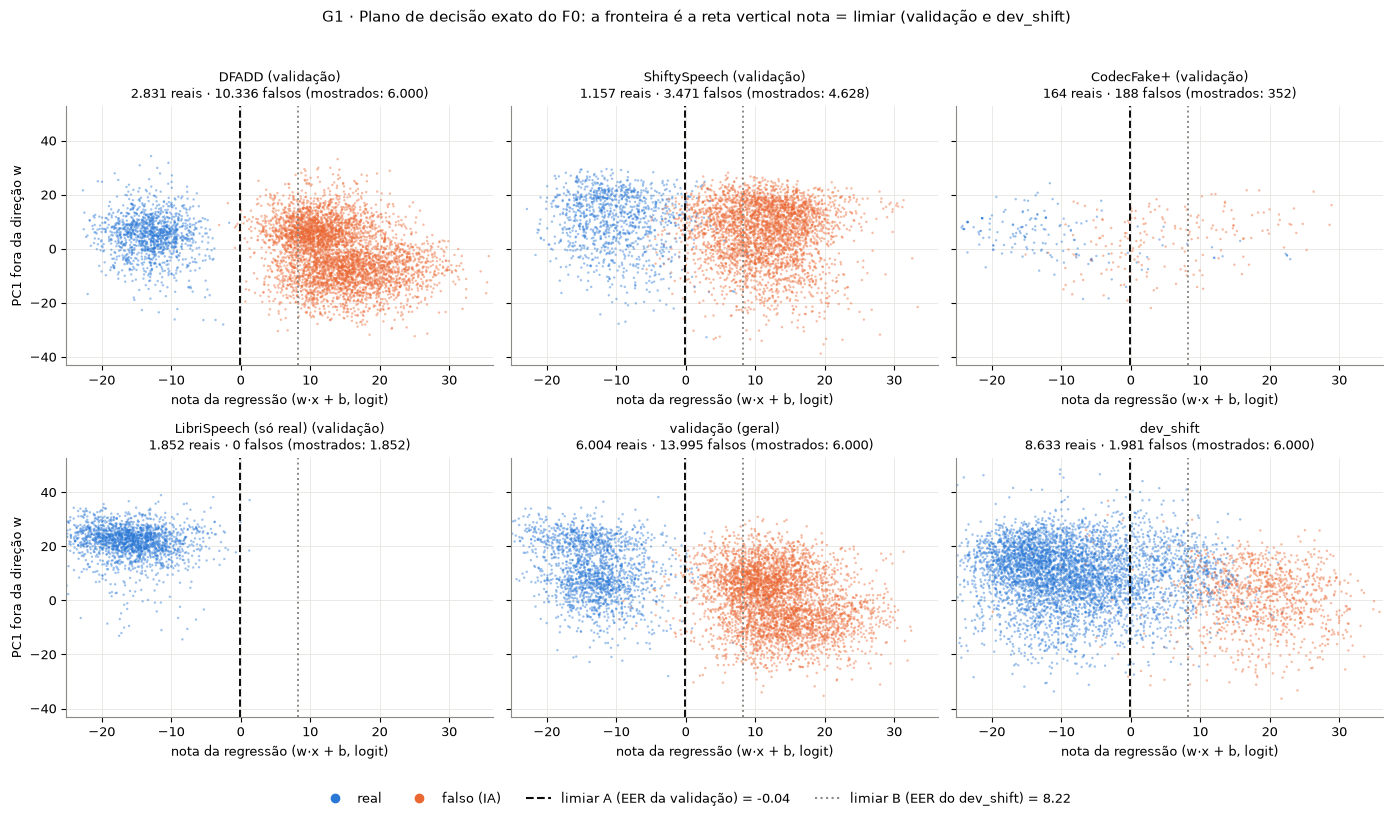

In [8]:
figura("g1_plano_decisao")

**O que olhar:** de que lado da reta tracejada cada cor cai; no DFADD e no LibriSpeech os reais ficam todos à esquerda, mas no dev_shift há uma "cauda" de reais (azul) passando da reta A, e o CodecFake+ (352 clipes) tem falsos dos dois lados. **O que concluir:** a regressão separa muito bem o mundo do treino, e o erro que sobra nas vozes de internet é de reais com nota alta, o que explica por que o limiar B (mais à direita) reduz o falso alarme ali; o eixo y explica só 11% da variação fora de w, então é uma fatia do espaço, não o espaço inteiro.

### G1-teste · O mesmo plano nos bancos de teste (SÓ VISUALIZAÇÃO, NÃO DECIDE NADA)

**O que faz:** O mesmo eixo x (nota) e o mesmo eixo y (calculado no treino) para In-the-Wild, LlamaPartialSpoof, BRSpeech-DF e CORAA, a partir do cache de teste. Nada aqui foi usado para escolher qualquer coisa.

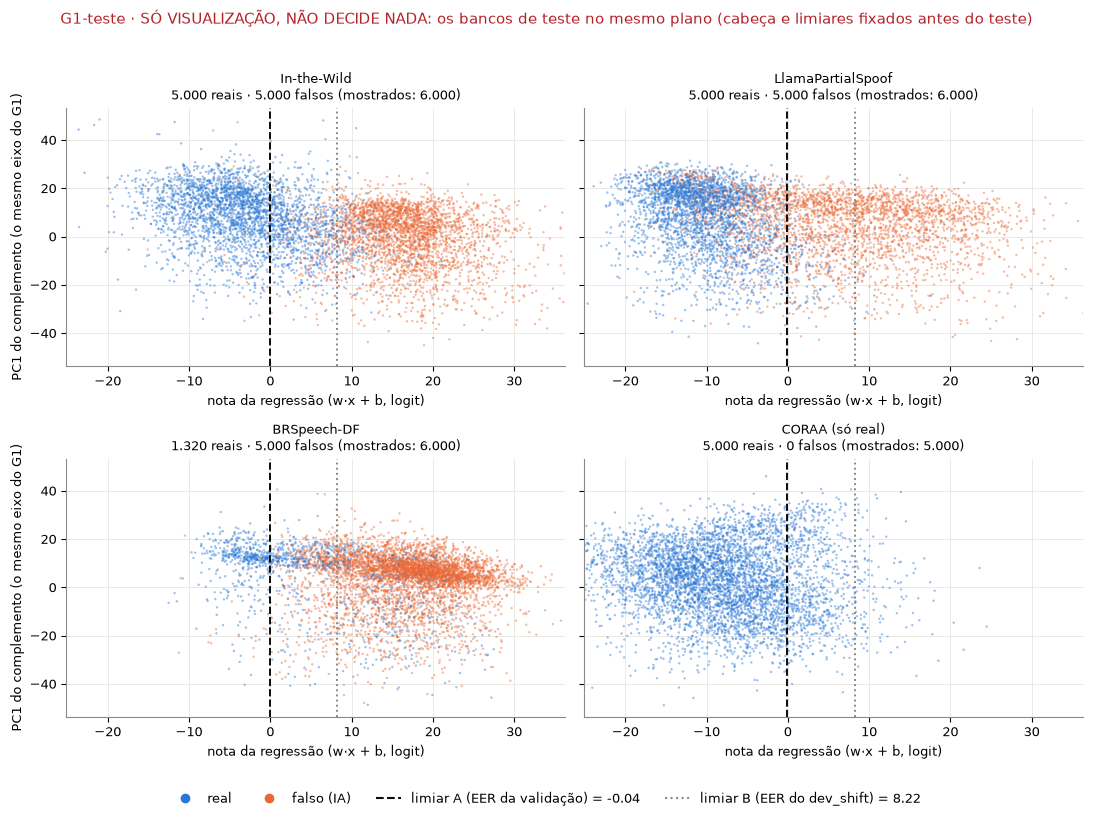

In [9]:
figura("g1_plano_decisao_teste")

**O que olhar:** no BRSpeech-DF uma boa parte dos reais (azul) fica à direita da reta A, e no CORAA (só reais) também há reais à direita; no LlamaPartialSpoof, falsos (laranja) à esquerda. **O que concluir:** os erros do teste são do mesmo tipo do dev_shift (reais com nota alta, sobretudo em português) mais falsos parciais que passam; a figura não diz por quê, e não deve ser usada para mexer no limiar.

### G2 · Distribuição da nota, real × falso, por banco

**O que faz:** Histograma (densidade por classe) da nota do F0 na validação, no dev_shift e nos bancos de teste, com os limiares A e B.

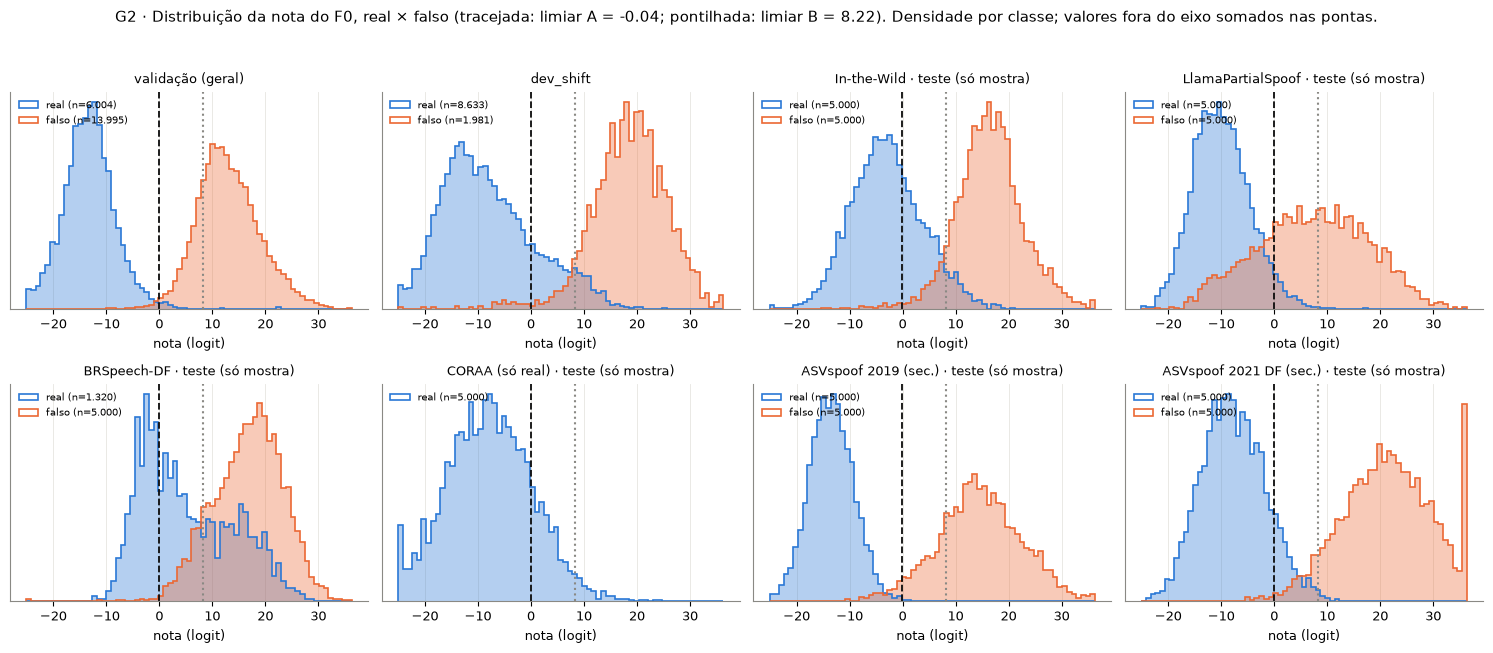

In [10]:
figura("g2_histogramas")

**O que olhar:** a distância entre as duas montanhas e onde ficam os limiares; na validação elas quase não se tocam, no In-the-Wild e no dev_shift os reais se deslocam para a direita, e no BRSpeech-DF os reais têm duas montanhas (uma delas no meio dos falsos). **O que concluir:** o limiar A (estúdio) fica cedo demais para as vozes de internet e para o português, o que produz falso alarme; o limiar B corrige parte disso mas deixa passar mais falsos (LlamaPartialSpoof); por que parte dos reais do BRSpeech-DF tem nota alta **não foi investigado** (o banco mistura pt-BR e pt-PT, é uma hipótese, não um achado).

### G3 · Os vetores crus, sem a regressão (PCA e t-SNE)

**O que faz:** 3.000 clipes da validação + 3.000 do dev_shift, na melhor camada sozinha (7) e na última (24), **sem padronizar e sem a regressão**. Cada projeção aparece duas vezes: cor por real × falso e cor por origem (validação × dev_shift). Diferente do G1, aqui ninguém escolheu a direção a favor dos rótulos. ⚠️ Fora da trilha: PCA e t-SNE.

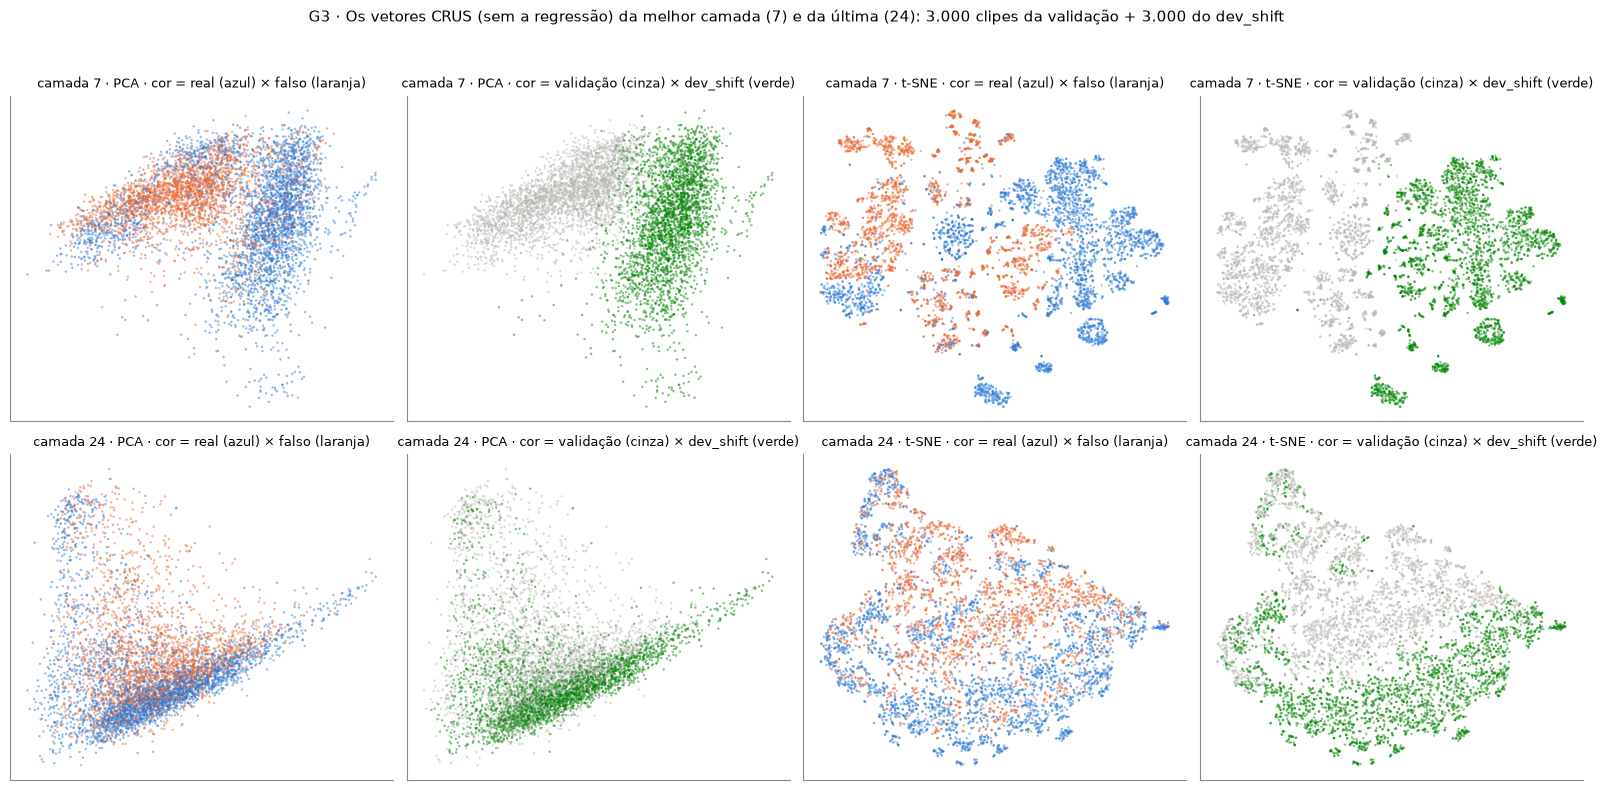

In [11]:
figura("g3_projecao")

**O que olhar:** na camada 7, as cores real/falso já formam grupos separados, mas a maior separação visível é **validação × dev_shift** (o tipo de gravação); na camada 24 tudo se mistura mais. **O que concluir:** os vetores do modelo pronto carregam muita informação de "de onde veio a gravação", e a regressão do G1 é o que acha a direção real × falso no meio disso; o t-SNE distorce distâncias, então só os agrupamentos (não as posições) têm leitura.

### G4 · AUC e EER por camada

**O que faz:** Uma regressão logística por camada (C de cada uma pela validação), lida de `results/v4_camadas.csv`. Faixas verdes: as camadas do F0; tracejada: a 24 (S1).

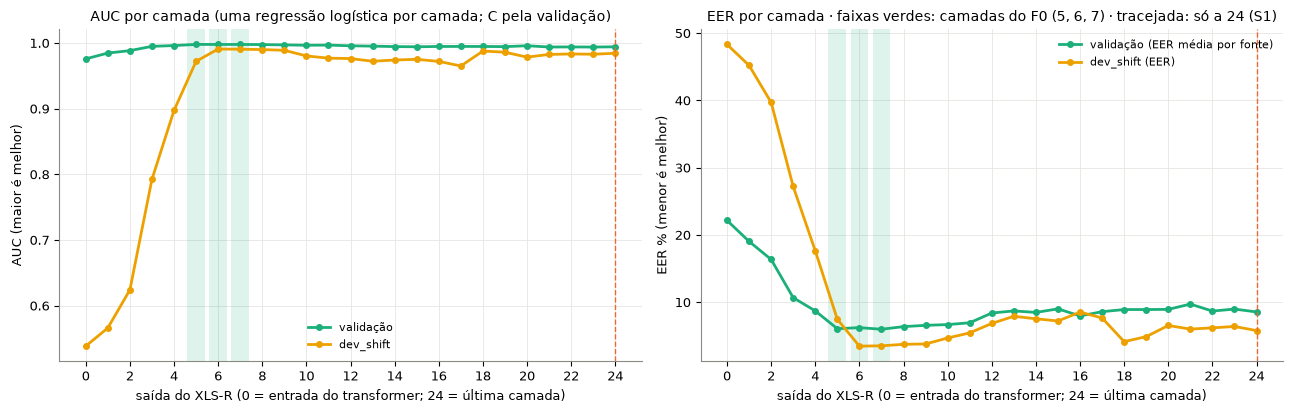

In [12]:
figura("g4_camadas")

**O que olhar:** as camadas 0 a 3 quase não servem no dev_shift (AUC 0,54 a 0,79), e da 5 em diante tudo passa de 0,97; as camadas 5 a 7 têm a menor EER na validação e no dev_shift. **O que concluir:** as pistas úteis estão nas camadas do meio do XLS-R, e a escolha pela validação caiu na região certa também para o dev_shift; mas a última camada (24) já é quase tão boa no dev_shift, o que bate com o S1 no teste.

### G5 · Quanto cada camada pesa dentro do F0

**O que faz:** Soma dos valores absolutos dos 1.024 pesos de cada camada na regressão final (as entradas são padronizadas, então os pesos são comparáveis), e a distribuição dos pesos dentro de cada camada.

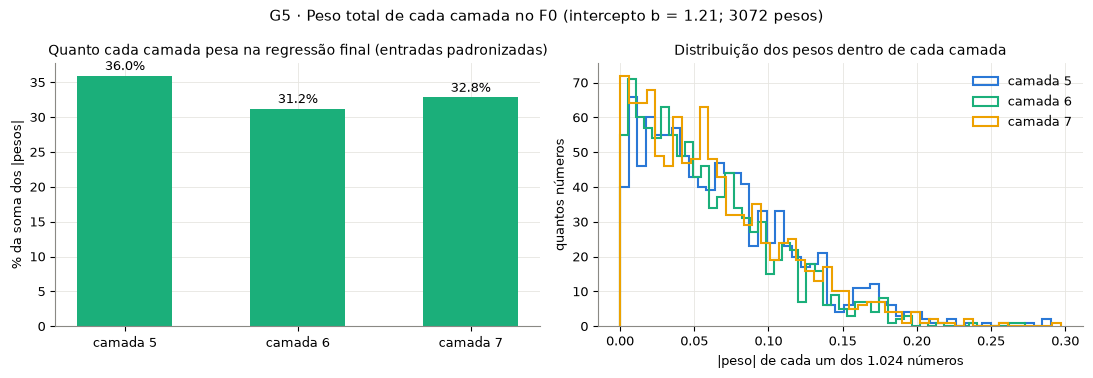

In [13]:
figura("g5_pesos_camadas")

**O que olhar:** as três barras são parecidas (36%, 31% e 33%) e as distribuições dos pesos se sobrepõem. **O que concluir:** a regressão usa as três camadas quase por igual, sem uma dominar; como as camadas vizinhas são muito parecidas (correlacionadas), o peso de cada uma não diz o quanto ela é "necessária" (tirar uma provavelmente mudaria pouco, mas isso não foi testado aqui).

### G6 · Curva de aprendizado (diagnóstico)

**O que faz:** O F0 (mesmas camadas, C = 0,1) treinado em 2 mil, 5 mil, 10 mil, 20 mil e 40 mil clipes (metade real, metade falso, sorteio com seed 42, um sorteio por tamanho). Acurácia balanceada no limiar A de cada modelo e AUC, no próprio treino, na validação e no dev_shift.

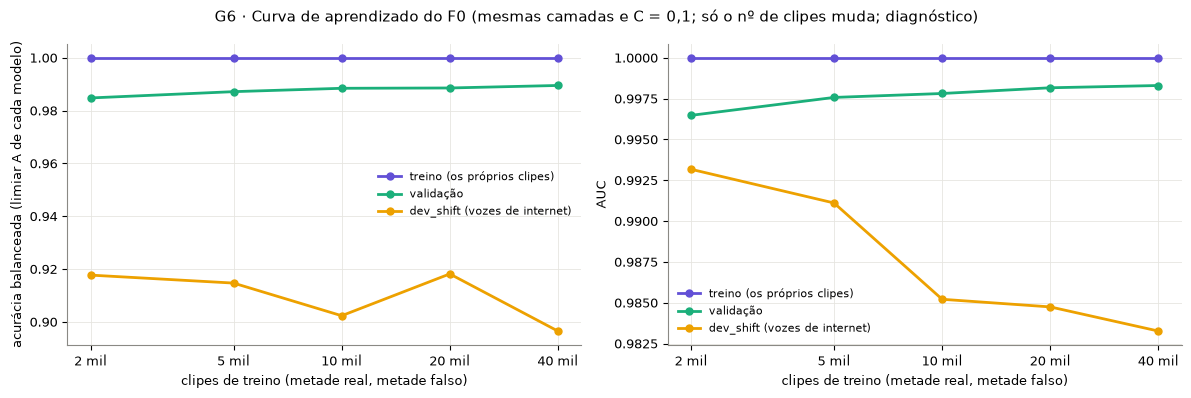

In [14]:
figura("g6_curva_aprendizado")

**O que olhar:** o treino fica em 1,00 em todos os tamanhos; a validação sobe devagar (AUC 0,996 → 0,998); o dev_shift **não sobe**: a AUC cai de 0,993 (2 mil) para 0,983 (40 mil). **O que concluir:** mais clipes do mesmo mundo (estúdio) ajudam a validação, mas não as vozes de internet; a regressão acerta 100% do próprio treino, que é o sinal de que ela consegue decorar o treino (overfitting, Aula 7); é um sorteio por tamanho, sem repetição, então a ordem exata dos pontos pode ser acaso.

### G7 · Caminho do C (diagnóstico)

**O que faz:** A mesma regressão com 11 valores de C (0,0001 a 10, escala log). O F0 usa C = 0,1, escolhido na grade da v4 (linhas tracejadas) pela EER média por fonte da validação.

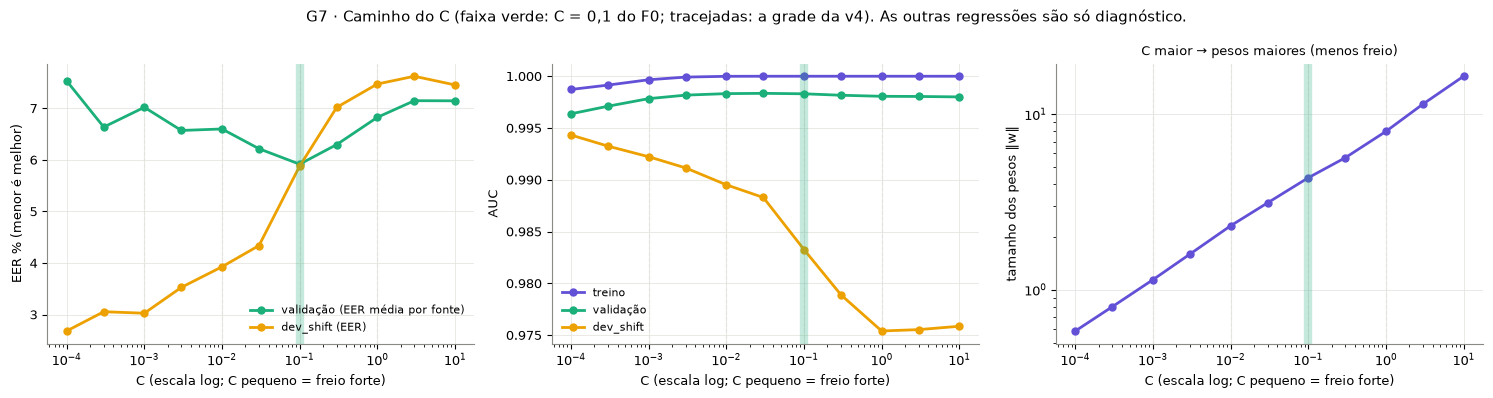

In [15]:
figura("g7_caminho_c")

**O que olhar:** a validação tem o mínimo perto de C = 0,1, mas o dev_shift melhora sem parar quando o freio aumenta (C = 0,0001: EER 2,7% e AUC 0,994, contra 5,9% e 0,983 no F0), enquanto os pesos encolhem (painel da direita). **O que concluir:** um freio mais forte (mais regularização) parece generalizar melhor para fora do estúdio, o mesmo tema da v6 (C = 1 piorou o português); isto é diagnóstico, feito depois de olhar o dev_shift, com 16 locutores: **não muda o F0**, e só valeria como hipótese para uma versão nova, confirmada num banco nunca visto.

### G8 · Calibração (probabilidade prevista × frequência real)

**O que faz:** Os áudios agrupados por faixa de probabilidade prevista (0 a 0,1, 0,1 a 0,2…); para cada faixa, a fração que é falsa de verdade. Os números são os clipes de cada faixa. ⚠️ Fora da trilha: calibração e Brier.

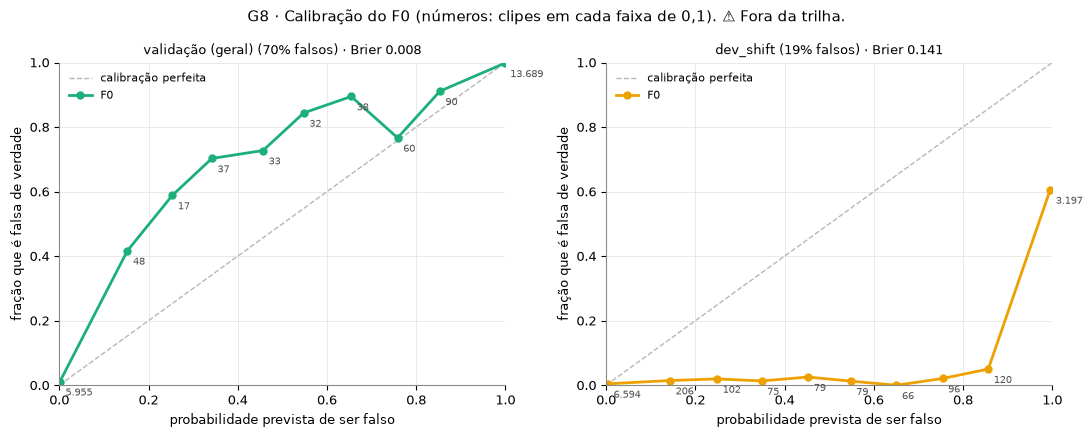

In [16]:
figura("g8_calibracao")

**O que olhar:** na validação quase todos os clipes estão nas pontas (0 a 0,1 e 0,9 a 1) e a curva fica acima da diagonal no meio (poucos clipes); no dev_shift, entre 0,1 e 0,9 quase nada é falso, e na faixa 0,9 a 1 só 61% é falso. **O que concluir:** a nota ordena bem, mas a probabilidade não deve ser lida como "chance de ser IA" fora do estúdio: no dev_shift, "99% falso" está errado 4 em cada 10 vezes; a proporção de falsos também muda entre os conjuntos (70% na validação, 19% no dev_shift), e a calibração depende dela.

### G9 · Curva ROC por banco de teste (só mostra)

**O que faz:** A curva ROC do F0 em cada banco de teste com duas classes, com os pontos de operação dos limiares A (●) e B (■).

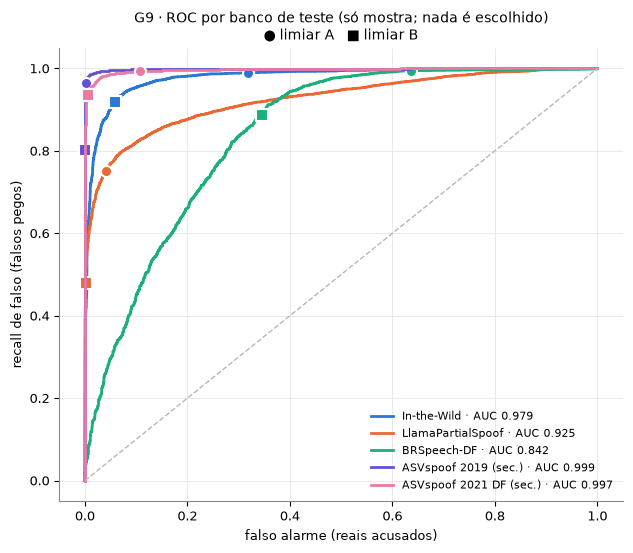

In [17]:
figura("g9_roc")

**O que olhar:** a curva do BRSpeech-DF fica bem abaixo das outras, e os pontos A e B ficam em lugares diferentes de cada curva. **O que concluir:** a ordenação é boa em inglês (AUC 0,925 a 0,999) e fraca em português (0,842); a troca entre falso alarme e falsos que passam depende do limiar, e nenhum dos dois é bom em todos os bancos.

### G9 · Matrizes de confusão no teste, limiares A e B (só mostra)

**O que faz:** Contagens e porcentagem por linha (linha = verdade). CORAA só tem reais.

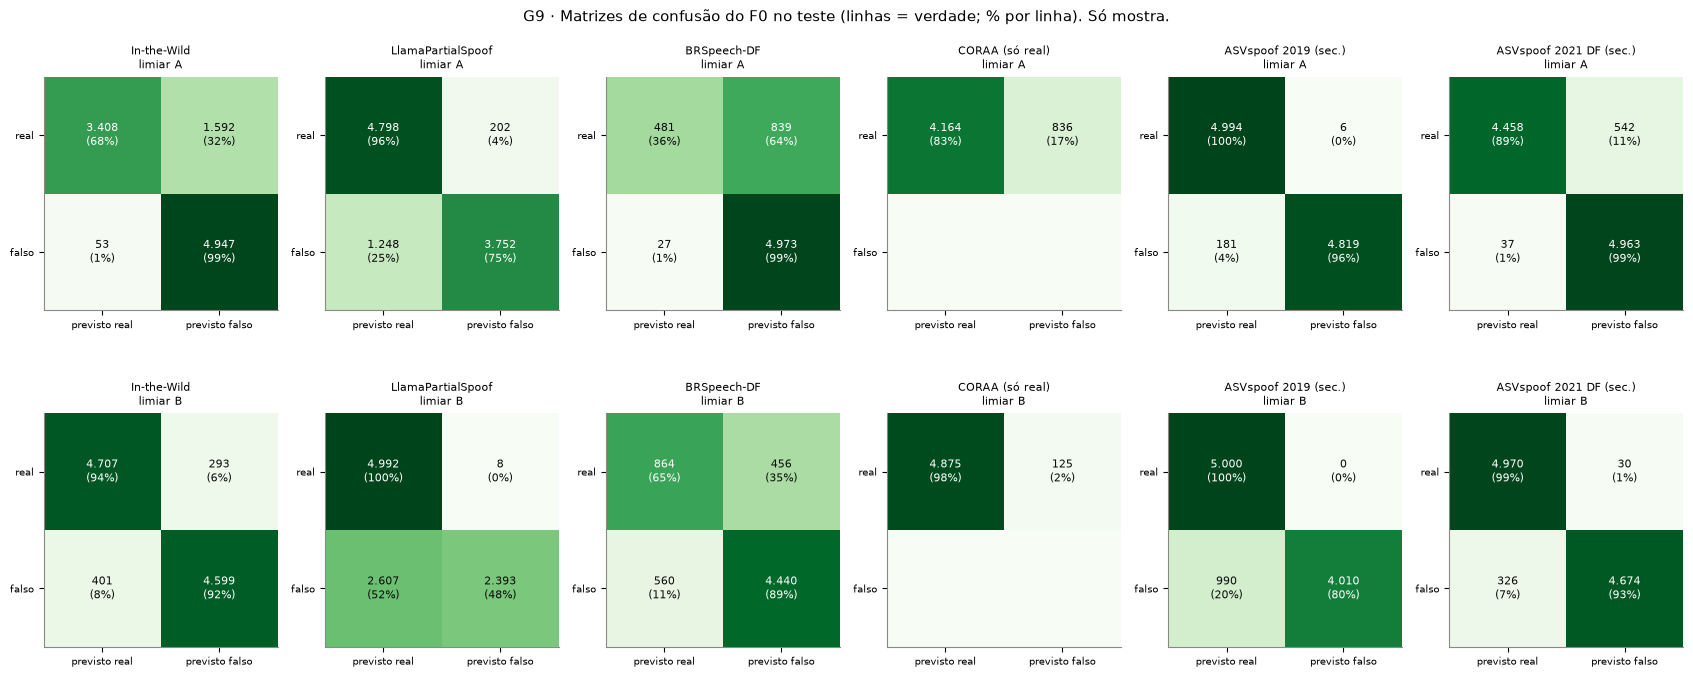

In [18]:
figura("g9_confusao")

**O que olhar:** no limiar A, 32% dos reais do In-the-Wild e 64% dos reais do BRSpeech-DF são acusados; no limiar B, 52% dos falsos do LlamaPartialSpoof passam. **O que concluir:** os dois limiares trocam um erro pelo outro; o pior caso é o BRSpeech-DF, ruim nos dois.

### G10 · Acurácia por banco: F0 × CNN antiga (S0) × chute da classe comum

**O que faz:** Lido de `results/v4_teste_final.csv` (teste da v4, avaliado uma vez). S0 é a CNN da v3 com menor EER média por fonte na validação. No CORAA (só reais), acurácia = 1 − falso alarme, e o "chute" (sempre real) acerta 100%.

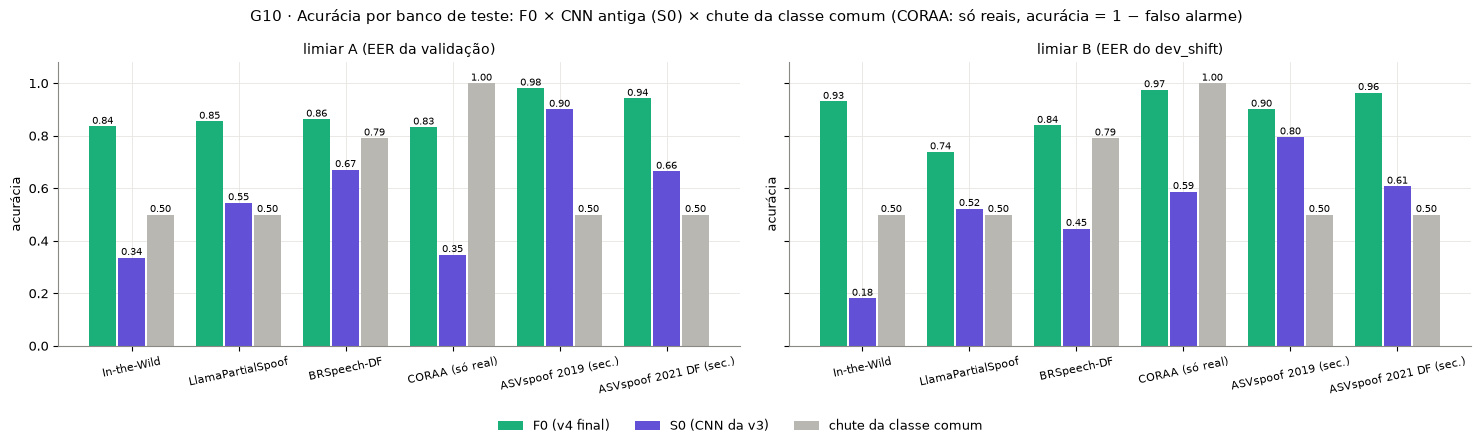

In [19]:
figura("g10_acuracia_bancos")

**O que olhar:** no In-the-Wild a CNN fica abaixo do chute (0,34 contra 0,50) e o F0 vai a 0,84 (A) / 0,93 (B); no BRSpeech-DF, com o limiar A, o F0 (0,86) mal passa do chute (0,79), porque 79% do banco é falso. **O que concluir:** o F0 é muito melhor que a CNN em todos os bancos; a acurácia sozinha engana em banco desbalanceado (BRSpeech-DF, CORAA), por isso a acurácia balanceada e a AUC vêm junto (seção 8).

### G11 · Falso alarme e falso que passa, por fonte e por banco

**O que faz:** Os dois erros nos limiares A e B: % de reais acusados e % de falsos que passam como reais, nas fontes da validação, no dev_shift e nos bancos de teste (só mostra).

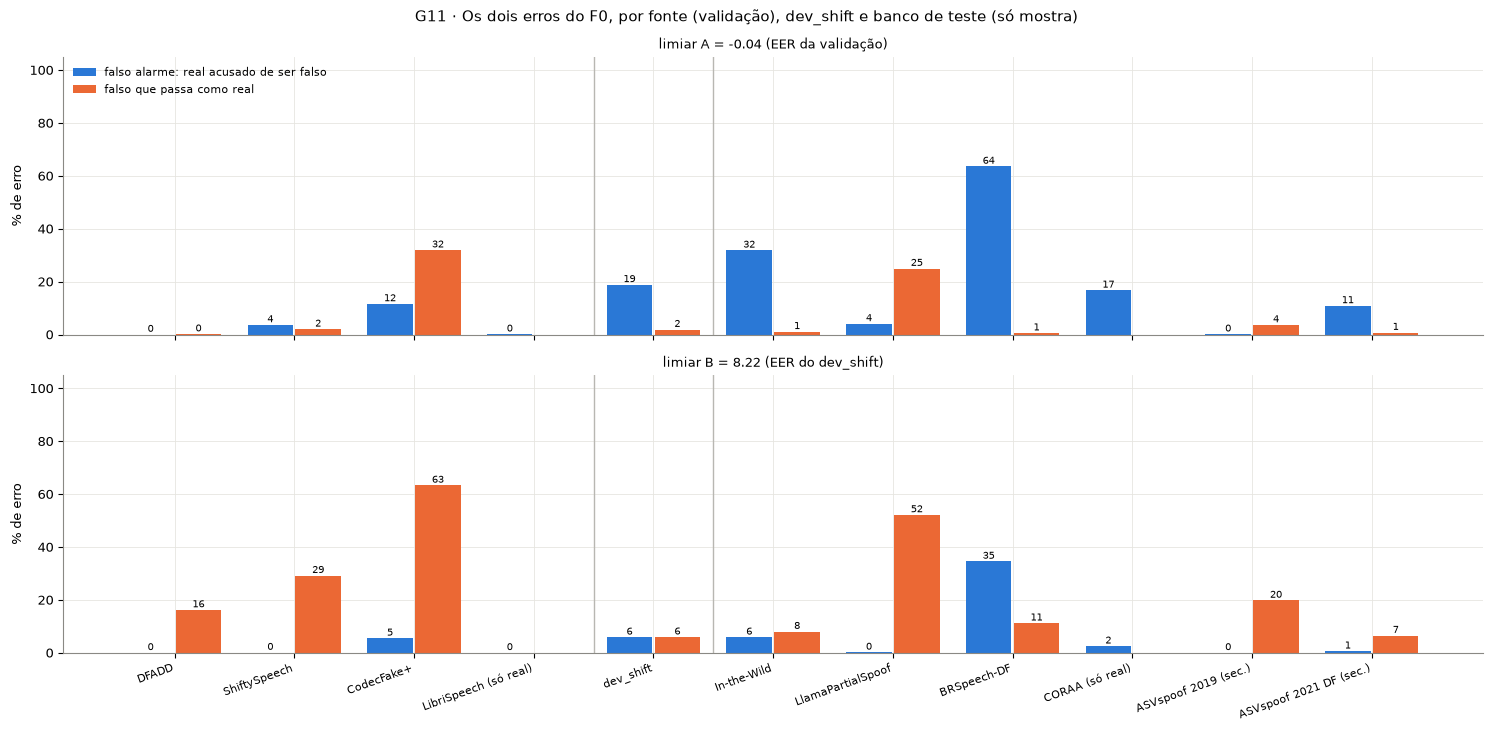

In [20]:
figura("g11_erros")

**O que olhar:** no limiar A, o falso alarme é baixo no estúdio (0 a 12%) e alto no dev_shift (19%), In-the-Wild (32%), BRSpeech-DF (64%) e CORAA (17%); no limiar B ele cai, mas os falsos que passam sobem (CodecFake+ 63%, LlamaPartialSpoof 52%). **O que concluir:** o limiar escolhido no estúdio não serve para o mundo real, e o escolhido nas vozes de internet deixa passar fakes de outros tipos; um limiar por domínio é a ideia que ficou para depois (não testada).

### G12 · AUC por faixa de duração original

**O que faz:** AUC do F0 por duração original do arquivo (< 2 s, 2 a 4 s, ≥ 4 s) no dev_shift e nos bancos de teste, com o número de clipes.

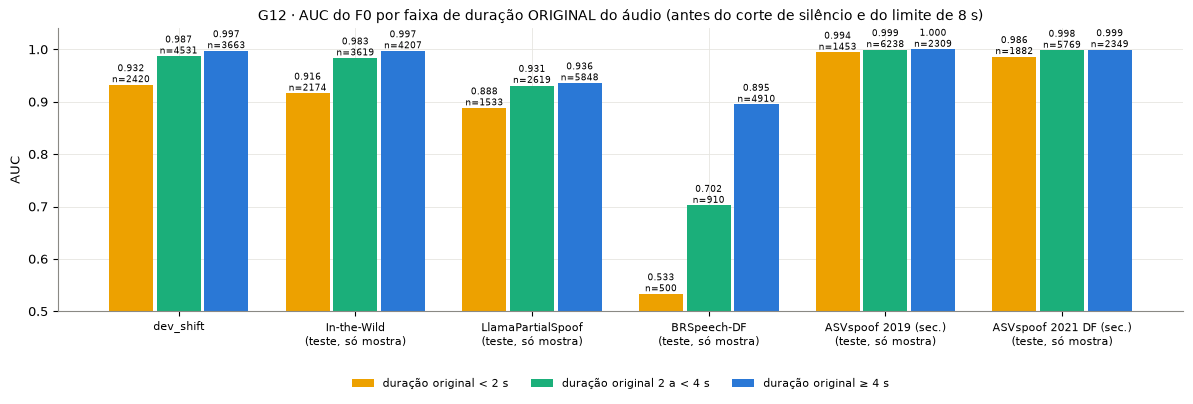

In [21]:
figura("g12_duracao")

**O que olhar:** em todos os bancos os áudios curtos são os piores; no BRSpeech-DF, abaixo de 2 s a AUC é 0,533 (quase acaso, 500 clipes) e de 2 a 4 s é 0,702. **O que concluir:** áudio curto é um ponto fraco geral, e o português curto é onde o sistema praticamente não funciona; a duração se mistura com outras diferenças (locutor, gravador), então é associação, não causa.

### G13 · Recall por gerador na validação

**O que faz:** % dos falsos pegos por gerador (barra: limiar A; traço: limiar B). Cor = fonte. No CodecFake+, cada gerador tem de 5 a 32 falsos.

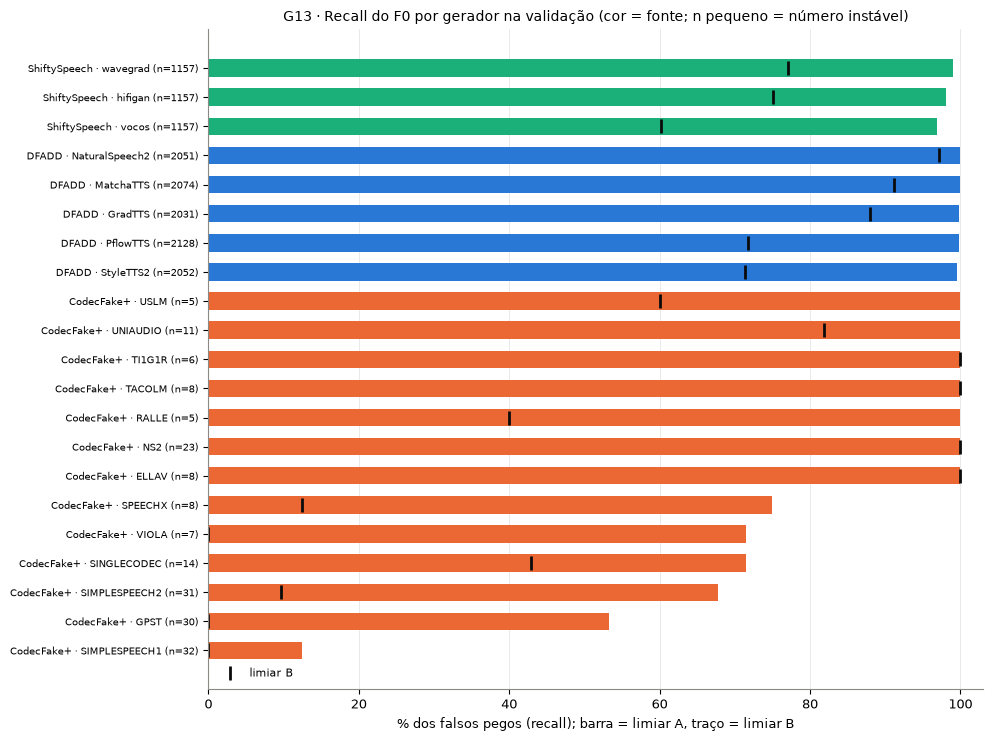

In [22]:
figura("g13_geradores")

**O que olhar:** DFADD e ShiftySpeech ficam perto de 100% no limiar A; no CodecFake+ alguns geradores escapam muito (SIMPLESPEECH1 12%, GPST 53%, SIMPLESPEECH2 68%). **O que concluir:** os fakes de codec neural são o tipo mais difícil dentro da validação; com tão poucos clipes por gerador, os números são instáveis e servem de pista, não de ranking.

### G14 · AUC/EER por camada, Meta × Microsoft

**O que faz:** Os dois modelos prontos, camada por camada: **v5, feita pelo colega David Chung** (EER na validação e AUC no dev_shift; `results/v5_comparacao_camadas.csv`) e v6 (AUC da pior fonte, nesta máquina, nos mesmos clipes; `results/v6_e1_camadas.csv`).

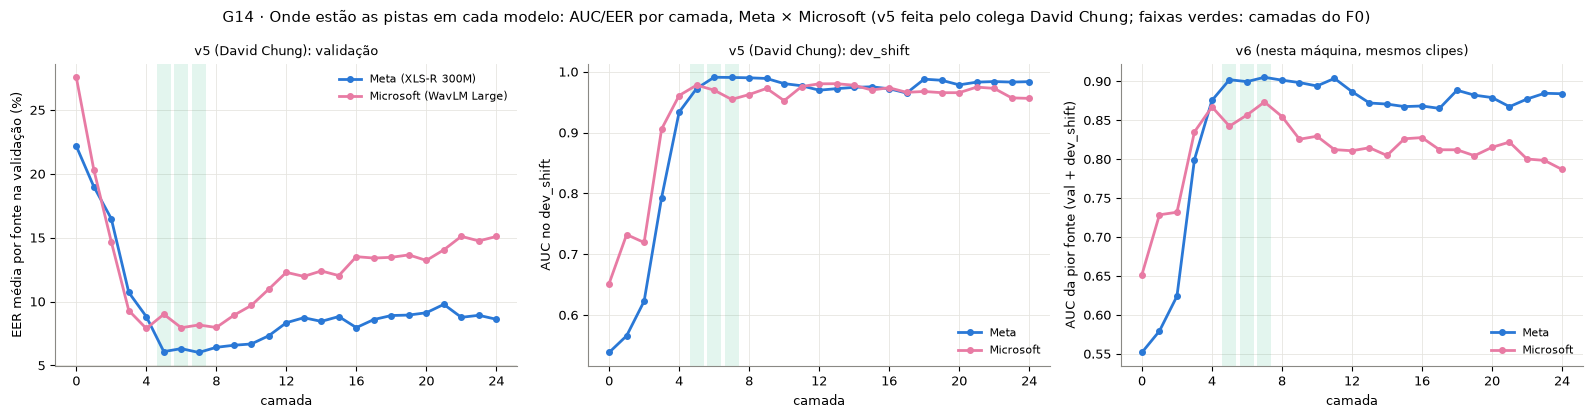

In [23]:
figura("g14_meta_microsoft")

**O que olhar:** no WavLM (Microsoft) as melhores camadas são as de baixo (3 e 4) e a qualidade cai depois da 8; no XLS-R (Meta) as camadas 5 a 9 ficam todas boas e as de cima pioram pouco. **O que concluir:** os dois modelos guardam as pistas em lugares diferentes e o XLS-R foi melhor no conjunto (sobretudo em português, no teste da v5); a explicação (o pré-treino do WavLM a "limpar" ruído descartaria os artefatos nas camadas de cima) é hipótese, não testada.

**O que faz:** mostra as tabelas por trás de G6, G7, G11, G12 e G13. **Por quê:** os números exatos dos gráficos.

In [24]:
for nome in ("g6_curva_aprendizado", "g7_caminho_c", "g11_erros", "g12_duracao", "g13_geradores"):
    display(Markdown(f"**`results/v4final_{nome}.csv`**"))
    tabela(f"v4final_{nome}.csv", 4)

**`results/v4final_g6_curva_aprendizado.csv`**

,clipes de treino,treino acc. bal. (lim. A),val acc. bal. (lim. A),dev acc. bal. (lim. A),treino AUC,val AUC,dev AUC,val EER média por fonte,dev EER,limiar A (logit),iterações,segundos
0,2000,1.0,0.9848,0.9177,1.0,0.9965,0.9932,0.0629,0.0342,0.2152,43,0.2
1,5000,1.0,0.9872,0.9147,1.0,0.9976,0.9911,0.0701,0.0388,0.1274,51,0.5
2,10000,1.0,0.9885,0.9023,1.0,0.9978,0.9852,0.0668,0.0480,0.1893,58,0.7
3,20000,1.0,0.9886,0.9182,1.0,0.9982,0.9847,0.0556,0.0493,0.1193,61,1.2
4,40000,1.0,0.9895,0.8965,1.0,0.9983,0.9833,0.0592,0.0588,-0.0395,56,0.4


**`results/v4final_g7_caminho_c.csv`**

,C,na grade da v4,treino acc. bal. (lim. A),val acc. bal. (lim. A),dev acc. bal. (lim. A),treino AUC,val AUC,dev AUC,val EER média por fonte,dev EER,limiar A (logit),iterações,norma de w,segundos
0,0.0001,False,0.9924,0.9852,0.9455,0.9987,0.9964,0.9943,0.0753,0.0268,0.1615,30,0.5819,1.2
1,0.0003,False,0.9945,0.9870,0.9381,0.9991,0.9971,0.9932,0.0664,0.0305,0.2152,36,0.8010,1.3
2,0.0010,True,0.9964,0.9892,0.9268,0.9997,0.9978,0.9922,0.0702,0.0303,0.2514,47,1.1415,1.5
3,0.0030,False,0.9977,0.9890,0.9179,0.9999,0.9982,0.9911,0.0657,0.0353,0.2600,56,1.5983,1.8
4,0.0100,True,0.9990,0.9895,0.9133,1.0000,0.9983,0.9895,0.0660,0.0393,0.3100,67,2.3164,1.9
5,0.0300,False,0.9998,0.9898,0.9077,1.0000,0.9983,0.9883,0.0622,0.0434,0.2955,81,3.1327,2.3
6,0.1000,True,1.0000,0.9895,0.8965,1.0000,0.9983,0.9833,0.0592,0.0588,-0.0395,56,4.3518,0.2
7,0.3000,False,1.0000,0.9877,0.8974,1.0000,0.9982,0.9789,0.0630,0.0702,0.5674,39,5.6632,1.3
8,1.0000,True,0.9999,0.9857,0.8957,1.0000,0.9981,0.9754,0.0682,0.0747,1.8138,35,7.9997,1.2
9,3.0000,False,0.9998,0.9858,0.8872,1.0000,0.9980,0.9755,0.0715,0.0762,1.3398,28,11.4527,1.0


**`results/v4final_g11_erros.csv`**

,grupo,conjunto,limiar,falso alarme (reais acusados),falsos que passam (1 − recall),n real,n fake
0,dfadd,validação,A,0.0000,0.0016,2831,10336
1,dfadd,validação,B,0.0000,0.1620,2831,10336
2,shiftyspeech,validação,A,0.0363,0.0199,1157,3471
3,shiftyspeech,validação,B,0.0009,0.2918,1157,3471
4,codecfake_plus,validação,A,0.1159,0.3191,164,188
5,codecfake_plus,validação,B,0.0549,0.6330,164,188
6,librispeech,validação,A,0.0011,NaN,1852,0
7,librispeech,validação,B,0.0000,NaN,1852,0
8,dev_shift,dev_shift,A,0.1882,0.0187,8633,1981
9,dev_shift,dev_shift,B,0.0585,0.0591,8633,1981


**`results/v4final_g12_duracao.csv`**

,conjunto,faixa,n,n real,n fake,AUC
0,dev_shift,< 2 s,2420,2067,353,0.9324
1,dev_shift,2 a < 4 s,4531,3772,759,0.9872
2,dev_shift,≥ 4 s,3663,2794,869,0.9973
3,in_the_wild,< 2 s,2174,1375,799,0.9163
4,in_the_wild,2 a < 4 s,3619,2036,1583,0.9835
5,in_the_wild,≥ 4 s,4207,1589,2618,0.9971
6,llamapartialspoof,< 2 s,1533,919,614,0.8881
7,llamapartialspoof,2 a < 4 s,2619,1312,1307,0.9311
8,llamapartialspoof,≥ 4 s,5848,2769,3079,0.9359
9,brspeech_df,< 2 s,500,127,373,0.5333


**`results/v4final_g13_geradores.csv`**

,fonte,gerador,n fakes,recall (lim. A),recall (lim. B)
0,codecfake_plus,SIMPLESPEECH1,32,0.1250,0.0000
1,codecfake_plus,GPST,30,0.5333,0.0000
2,codecfake_plus,SIMPLESPEECH2,31,0.6774,0.0968
3,codecfake_plus,SINGLECODEC,14,0.7143,0.4286
4,codecfake_plus,VIOLA,7,0.7143,0.0000
5,codecfake_plus,SPEECHX,8,0.7500,0.1250
6,codecfake_plus,ELLAV,8,1.0000,1.0000
7,codecfake_plus,NS2,23,1.0000,1.0000
8,codecfake_plus,RALLE,5,1.0000,0.4000
9,codecfake_plus,TACOLM,8,1.0000,1.0000


## 8. Resultados no teste (F0)

O teste foi avaliado **uma única vez**, na v4 (2026-11-10), pelo pré-registro, com até 5.000 clipes por classe e banco (seed 42); nada foi reescolhido depois. Os números abaixo são os gravados (`results/v4_teste_final.csv`) e o reajuste os reproduz (seção 7).

**O que faz:** tabela por banco com acurácia, acurácia balanceada, acurácia trivial, AUC, EER, recall de fake e falso alarme, nos limiares A e B, para o F0 (e, para comparar, S1 = só a camada 24 e S0 = a CNN da v3). **Por quê:** é o resultado final do sistema.

In [25]:
t8 = pd.read_csv(R / "v4final_teste_por_banco.csv")
cols = ["banco", "limiar", "acurácia", "acurácia balanceada", "acurácia trivial", "AUC", "EER", "recall fake",
        "falso alarme real", "acurácia balanceada IC95", "AUC IC95", "n real", "n fake"]
for s in ("F0 (v4 final)", "S1 (só camada 24)", "S0 (CNN da v3)"):
    display(Markdown(f"**{s}**"))
    display(t8[t8.sistema == s][cols].round(3))

**F0 (v4 final)**

,banco,limiar,acurácia,acurácia balanceada,acurácia trivial,AUC,EER,recall fake,falso alarme real,acurácia balanceada IC95,AUC IC95,n real,n fake
0,in_the_wild,A,0.836,0.835,0.500,0.979,0.068,0.989,0.318,0.829 a 0.842,0.976 a 0.981,5000,5000
1,in_the_wild,B,0.931,0.931,0.500,0.979,0.068,0.920,0.059,0.925 a 0.936,0.976 a 0.981,5000,5000
2,llamapartialspoof,A,0.855,0.855,0.500,0.925,0.147,0.750,0.040,0.849 a 0.862,0.920 a 0.930,5000,5000
3,llamapartialspoof,B,0.738,0.738,0.500,0.925,0.147,0.479,0.002,0.732 a 0.746,0.920 a 0.930,5000,5000
4,brspeech_df,A,0.863,0.679,0.791,0.842,0.249,0.995,0.636,0.667 a 0.693,0.827 a 0.854,1320,5000
5,brspeech_df,B,0.839,0.771,0.791,0.842,0.249,0.888,0.345,0.757 a 0.785,0.827 a 0.854,1320,5000
6,coraa,A,0.833,NaN,1.000,NaN,NaN,NaN,0.167,NaN,NaN,5000,0
7,coraa,B,0.975,NaN,1.000,NaN,NaN,NaN,0.025,NaN,NaN,5000,0
8,asvspoof2019_la,A,0.981,0.981,0.500,0.999,0.014,0.964,0.001,0.979 a 0.984,0.999 a 0.999,5000,5000
9,asvspoof2019_la,B,0.901,0.901,0.500,0.999,0.014,0.802,0.000,0.896 a 0.906,0.999 a 0.999,5000,5000


**S1 (só camada 24)**

,banco,limiar,acurácia,acurácia balanceada,acurácia trivial,AUC,EER,recall fake,falso alarme real,acurácia balanceada IC95,AUC IC95,n real,n fake
12,in_the_wild,A,0.829,0.829,0.500,0.986,0.054,0.992,0.333,0.823 a 0.836,0.985 a 0.988,5000,5000
13,in_the_wild,B,0.946,0.946,0.500,0.986,0.054,0.946,0.054,0.941 a 0.950,0.985 a 0.988,5000,5000
14,llamapartialspoof,A,0.851,0.851,0.500,0.936,0.140,0.734,0.032,0.844 a 0.858,0.931 a 0.940,5000,5000
15,llamapartialspoof,B,0.734,0.734,0.500,0.936,0.140,0.468,0.001,0.726 a 0.740,0.931 a 0.940,5000,5000
16,brspeech_df,A,0.849,0.671,0.791,0.775,0.307,0.976,0.633,0.658 a 0.683,0.759 a 0.791,1320,5000
17,brspeech_df,B,0.762,0.716,0.791,0.775,0.307,0.795,0.364,0.701 a 0.729,0.759 a 0.791,1320,5000
18,coraa,A,0.644,NaN,1.000,NaN,NaN,NaN,0.356,NaN,NaN,5000,0
19,coraa,B,0.884,NaN,1.000,NaN,NaN,NaN,0.116,NaN,NaN,5000,0
20,asvspoof2019_la,A,0.974,0.974,0.500,0.997,0.023,0.954,0.006,0.971 a 0.977,0.996 a 0.998,5000,5000
21,asvspoof2019_la,B,0.902,0.902,0.500,0.997,0.023,0.804,0.000,0.896 a 0.908,0.996 a 0.998,5000,5000


**S0 (CNN da v3)**

,banco,limiar,acurácia,acurácia balanceada,acurácia trivial,AUC,EER,recall fake,falso alarme real,acurácia balanceada IC95,AUC IC95,n real,n fake
24,in_the_wild,A,0.336,0.336,0.500,0.114,0.822,0.633,0.960,0.329 a 0.343,0.107 a 0.120,5000,5000
25,in_the_wild,B,0.181,0.181,0.500,0.114,0.822,0.210,0.848,0.174 a 0.188,0.107 a 0.120,5000,5000
26,llamapartialspoof,A,0.545,0.545,0.500,0.556,0.463,0.762,0.672,0.536 a 0.554,0.545 a 0.568,5000,5000
27,llamapartialspoof,B,0.523,0.523,0.500,0.556,0.463,0.397,0.351,0.513 a 0.533,0.545 a 0.568,5000,5000
28,brspeech_df,A,0.671,0.704,0.791,0.735,0.293,0.647,0.239,0.691 a 0.717,0.719 a 0.751,1320,5000
29,brspeech_df,B,0.447,0.609,0.791,0.735,0.293,0.331,0.113,0.598 a 0.620,0.719 a 0.751,1320,5000
30,coraa,A,0.347,NaN,1.000,NaN,NaN,NaN,0.653,NaN,NaN,5000,0
31,coraa,B,0.587,NaN,1.000,NaN,NaN,NaN,0.413,NaN,NaN,5000,0
32,asvspoof2019_la,A,0.900,0.901,0.500,0.967,0.080,0.803,0.002,0.895 a 0.906,0.963 a 0.970,5000,5000
33,asvspoof2019_la,B,0.795,0.795,0.500,0.967,0.080,0.591,0.000,0.788 a 0.802,0.963 a 0.970,5000,5000


**O que faz:** a média da acurácia dos 3 bancos principais (In-the-Wild, LlamaPartialSpoof, BRSpeech-DF), o falso alarme do CORAA à parte, e a leitura pré-definida das diferenças pareadas (S2 − S1 = "nossas escolhas"; S3 − S2 = "juntar a CNN"). **Por quê:** é o resumo combinado antes do teste.

In [26]:
tr = ler(R / "v4_teste_final_resumo.json")
res = pd.DataFrame(tr["resumo"]).replace({"sistema": {"S2": "S2 = F0"}})
display(res.round(3))
display(Markdown("**Leitura pré-definida** (relevante só com o mesmo sinal nos 3 principais e IC95 sem o zero em cada um):"))
display(pd.Series(tr["regra_leitura"]).to_frame("resultado"))
dif = pd.read_csv(R / "v4_teste_diferencas.csv")
display(dif.round(4))

,sistema,limiar,média acurácia (3 principais),média acurácia balanceada (3 principais),média acurácia trivial (3 principais),média AUC (3 principais),coraa falso alarme,coraa falso alarme IC
0,S0,A,0.517,0.529,0.597,0.468,0.653,"[0.638795, 0.666]"
1,S0,B,0.384,0.438,0.597,0.468,0.413,"[0.399, 0.427]"
2,S1,A,0.843,0.784,0.597,0.899,0.356,"[0.342, 0.3688]"
3,S1,B,0.814,0.798,0.597,0.899,0.116,"[0.106595, 0.1252]"
4,S2 = F0,A,0.851,0.790,0.597,0.915,0.167,"[0.1568, 0.178]"
5,S2 = F0,B,0.836,0.813,0.597,0.915,0.025,"[0.0208, 0.0292]"
6,S3,A,0.778,0.728,0.597,0.876,0.318,"[0.3056, 0.3316]"
7,S3,B,0.767,0.763,0.597,0.876,0.087,"[0.0788, 0.0942]"


**Leitura pré-definida** (relevante só com o mesmo sinal nos 3 principais e IC95 sem o zero em cada um):

,resultado
contribuição das nossas escolhas (S2 − S1) | AUC,não demonstrada
"contribuição das nossas escolhas (S2 − S1) | acurácia balanceada, limiar A",não demonstrada
contribuição da CNN (S3 − S2) | AUC,não demonstrada
"contribuição da CNN (S3 − S2) | acurácia balanceada, limiar A",não demonstrada


,leitura,métrica,banco,tipo,diferença,"IC 2,5%","IC 97,5%",IC exclui zero
0,contribuição das nossas escolhas (S2 − S1),AUC,in_the_wild,principal,-0.0078,-0.0102,-0.0056,True
1,contribuição das nossas escolhas (S2 − S1),AUC,llamapartialspoof,principal,-0.0106,-0.0146,-0.0066,True
2,contribuição das nossas escolhas (S2 − S1),AUC,brspeech_df,principal,0.0661,0.0577,0.0753,True
3,contribuição das nossas escolhas (S2 − S1),AUC,asvspoof2019_la,secundário,0.0022,0.0015,0.0028,True
4,contribuição das nossas escolhas (S2 − S1),AUC,asvspoof2021_df,secundário,0.0006,-0.0002,0.0014,False
5,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",in_the_wild,principal,0.0063,-0.0011,0.0136,False
6,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",llamapartialspoof,principal,0.0039,-0.0022,0.0095,False
7,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",brspeech_df,principal,0.0081,-0.0011,0.0178,False
8,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",asvspoof2019_la,secundário,0.0072,0.0042,0.0103,True
9,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",asvspoof2021_df,secundário,-0.0144,-0.0192,-0.0095,True


**Conclusão do teste:**
- **F0:** AUC 0,979 (In-the-Wild), 0,925 (LlamaPartialSpoof), 0,842 (BRSpeech-DF); média da acurácia nos 3 principais **0,851** (limiar A) e 0,836 (B), contra **0,597** do chute da classe comum. CORAA: 16,7% (A) e 2,5% (B) dos reais acusados.
- **Secundários** (ASVspoof 2019 e 2021 DF, AUC 0,999 e 0,997): números altos, mas esses bancos podem ter locutores em comum com o treino (VCTK, via DFADD), então valem para geradores novos, não para locutores novos.
- **Nossas escolhas × só a última camada (S2 − S1): não demonstrada.** AUC −0,008 (In-the-Wild), −0,011 (LlamaPartialSpoof), +0,066 (BRSpeech-DF): sinais trocados. A única diferença grande a favor do F0 é no português (e no CORAA, 35,6% → 16,7% de falso alarme no A, só reportado).
- **CNN (S0) e juntar a CNN (S3):** a CNN ordena o In-the-Wild ao contrário (AUC 0,114); juntar a CNN ao F0 piorou o In-the-Wild em 0,091 de AUC.
- **Bootstrap:** os intervalos (±0,001 a ±0,016) medem **só a amostra de teste**; não medem o acaso do treino (uma única amostra de treino e uma regressão), que a v3 mostrou ser grande para a CNN.

## 9. O caminho até aqui (v1 a v6)

| versão | o que foi tentado | resultado | conclusão |
|:--|:--|:--|:--|
| v1 | CNN pequena em log-mel, sem augmentation | validação EER 1,3%; In-the-Wild AUC 0,211 | ótima em casa, invertida nas vozes de internet |
| v2 | regra do checkpoint (v1r), volume (v2a), ruído e canal (v2b); criação do dev_shift | dev_shift AUC 0,325 / 0,386 / 0,389 | robusta ao ruído que viu, sem ganho além do acaso; "limpo = real" não se confirmou |
| v3 | repetir × completar com zeros, 3 seeds | dev_shift AUC 0,146 a 0,378 nas seis execuções | sem efeito; a lição foi o **tamanho do acaso** |
| **v4** | **XLS-R congelado + regressão logística** (F0) | dev_shift 0,983; In-the-Wild 0,979; média de acurácia 0,851 | resolveu a inversão; fraco em português |
| v5 | WavLM Large (Microsoft) no lugar do XLS-R (**David Chung**) | empate no dev_shift; pior no teste em AUC nos 3 principais | segue o XLS-R |
| v6 | funil: Meta × Microsoft, fusão, RL × MLP × CNN, ajuste fino (pela AUC da pior fonte) | F2: média de acurácia 0,829 | pior que o F0 no teste; o notebook voltou ao F0 |

**A régua do ruído (v3):** com a mesma receita e só a seed mudando, a AUC do dev_shift da CNN variou de 0,146 a 0,378 (amplitude ~0,15 a 0,23); a acurácia balanceada, de 0,365 a 0,503. Diferenças menores que isso entre execuções únicas não são efeito. Na v4, as somas ponderadas com 3 seeds variaram só ~0,005 de AUC no dev_shift: com o modelo pronto, o acaso ficou muito menor.

**Meta × Microsoft:** na v5 (do colega David Chung), o WavLM ficou pior na validação (EER 6,77% × 5,92%) e no dev_shift (AUC 0,970 × 0,983, diferença não demonstrada pela regra), e pior no teste em AUC nos 3 principais (BRSpeech-DF 0,768 × 0,842). A v6 refez a comparação nesta máquina, nos mesmos clipes, e chegou ao mesmo lugar (G14).

**O funil da v6:** cada degrau comparou candidatos pela AUC da pior fonte (validação + dev_shift), com bootstrap por locutor, e só deixava entrar algo mais complexo com diferença relevante.

**O que faz:** mostra `results/v6_funil.csv` e os finalistas F0, F1 e F2 lado a lado no teste, com a acurácia trivial. **Por quê:** é a evidência de por que o notebook voltou ao F0.

In [27]:
fun = pd.read_csv(R / "v6_funil.csv")
display(fun[["etapa", "vencedor", "por quê", "AUC pior fonte (cada candidato)"]])
f012 = pd.read_csv(R / "v4final_f0_f1_f2.csv")
display(Markdown("**F0, F1 e F2 no teste (limiar A; F1 = camada 11, C = 1; F2 = F1 + pesos iguais por fonte):**"))
p = f012[f012.limiar == "A"].pivot_table(index="banco", columns="sistema", values=["acurácia", "acurácia balanceada", "AUC", "falso alarme real"], sort=False)
p[("acurácia trivial", "")] = f012[(f012.limiar == "A") & (f012.sistema == "F0")].set_index("banco")["acurácia trivial"]
display(p.round(3))

,etapa,vencedor,por quê,AUC pior fonte (cada candidato)
0,E1 Meta × Microsoft,empate (a E3 decide: fica o mais simples),Microsoft − Meta = -0.0166 (IC95 -0.0481 a +0.0011),Meta (concat_top4): 0.9072; Microsoft (concat_top3): 0.8906; v4 (referência)...
1,E2 fusão,fusão: média das notas,fica fusao_media: fusao_stacking − fusao_media: +0.0004 (IC95 -0.0005 a +0.0...,fusão: média das notas: 0.9051; fusão: stacking: 0.9055; fusão: vetores cola...
2,E3 front-end,só Meta (XLS-R),fica xlsr: wavlm − xlsr: -0.0166 (IC95 -0.0481 a +0.0011) → não relevante; f...,só Meta (XLS-R): 0.9072; só Microsoft (WavLM): 0.8906; fusão: média das nota...
3,E4 cabeças básicas,RL,"fica RL: MLP − RL por seed: +0.0079, +0.0018, -0.0015 → não relevante nas 3;...",RL básica: 0.9037; MLP básico s42: 0.9116; MLP básico s123: 0.9056; MLP bási...
4,E5 maximização,pesos iguais por fonte (sample_weight),pior fonte final 0.9100; regra de limiar A,passo 1: zona de camadas: {'xlsr': [11]}: 0.9037; passo 2: grade ampla de C:...
5,"E6 teste (uma vez, só mostra)",— (o teste não escolhe),F0: média da acurácia nos 3 principais 0.851 (trivial 0.597); F1: média da a...,"F0: v4: XLS-R (Meta) concat_top3 (camadas 5, 6, 7) + RL, C = 0,1: 0.9031; F1..."


**F0, F1 e F2 no teste (limiar A; F1 = camada 11, C = 1; F2 = F1 + pesos iguais por fonte):**

acurácia               acurácia balanceada                  AUC               falso alarme real               acurácia trivial
sistema                 F0     F1     F2                  F0     F1     F2     F0     F1     F2                F0     F1     F2                 
banco                                                                                                                                           
in_the_wild          0.836  0.807  0.812               0.835  0.807  0.812  0.979  0.972  0.972             0.318  0.377  0.366            0.500
llamapartialspoof    0.855  0.863  0.863               0.855  0.863  0.863  0.925  0.940  0.937             0.040  0.040  0.043            0.500
brspeech_df          0.863  0.814  0.813               0.679  0.576  0.571  0.842  0.741  0.744             0.636  0.833  0.845            0.791
coraa                0.833  0.588  0.596                 NaN    NaN    NaN    NaN    NaN    NaN             0.167  0.412  0.404            1.000
asvspoof2019_la      0.981  0.975  0.975               0.981  0.975  0.975  0.999  0.997  0.997             0.001  0.006  0.007            0.500
asvspoof2021_df      0.942  0.954  0.950               0.942  0.954  0.950  0.997  0.996  0.996             0.108  0.078  0.088            0.500

**A lição honesta da v6:** o sistema declarado pelo funil (F2) ficou **pior no teste que o F0** (média da acurácia nos 3 principais 0,829 × 0,851; BRSpeech-DF AUC 0,744 × 0,842; CORAA 40,4% × 16,7% de falso alarme no limiar A). A validação e o dev_shift (16 locutores) **não distinguiram** os dois: na AUC da pior fonte, F0 0,903 e F2 0,910. Causas prováveis, todas **HIPÓTESES**: (1) F1 e F2 usam **uma** camada (a 11), o F0 usa **três** (5, 6, 7); (2) F1 e F2 usam C = 1 (freio fraco), o F0 usa C = 0,1 (o G7 sugere que mais freio generaliza melhor); (3) a "pior fonte" foi sempre o CodecFake+ (352 clipes, inglês, codec), que não representa o português.

## 10. Limitações

- **Os bancos de teste foram vistos três vezes** (v4, v5 e v6). Os números do F0 são os da v4 original (o primeiro olhar), mas os bancos já não são "nunca vistos".
- **dev_shift pequeno:** 16 locutores; é ele que define o limiar B e que decidiu entre versões.
- **Uma única amostra de treino** (40.000 clipes) e uma regressão: o bootstrap do teste não mede o acaso do treino.
- **O português é o ponto fraco:** BRSpeech-DF com acurácia balanceada ~0,68 no limiar A (0,77 no B); áudios de menos de 2 s quase no acaso (G12); CORAA com 16,7% de reais acusados no limiar A.
- **Os dois limiares trocam um erro pelo outro:** A acusa reais de internet e de português; B deixa passar falsos parciais e de codec (G11).
- **A decisão de voltar ao F0 veio depois de ver o teste da v6.** O F0 em si foi escolhido pela validação **antes de qualquer teste** (pré-registro da v4), por isso os números do F0 são os da v4 original; mas preferir o F0 ao F2 agora é uma escolha informada pelo teste. **Recomendação:** antes de apresentar um número final como definitivo, avaliar o F0 **uma vez** num banco nunca visto (por exemplo, um banco do grupo que nunca tenha decidido nada), com o limiar declarado antes.
- **Explicações não provadas:** por que o modelo pronto funciona (seção 4), por que o WavLM perdeu e por que o F2 piorou são hipóteses.

## 11. Próximos passos (não executados)

1. **Melhorar a regressão logística** (um colega do grupo vai tentar): por exemplo, testar um freio mais forte (G7), sempre escolhendo pela validação + dev_shift e confirmando num banco novo.
2. **Dados em português e fala espontânea no treino** (reais pt-BR e fakes pt-BR de geradores fora dos testes), e um conjunto de decisão em português, para que as escolhas deixem de piorar o português sem ninguém ver.
3. **O contexto de golpes:** áudio curto, de telefone ou de aplicativo de mensagem, onde o sistema é mais fraco (G12); definir o limiar pelo custo de cada erro nesse uso.
4. **O modelo final unificado:** um único pipeline (áudio → XLS-R → regressão → nota e decisão) empacotado para o grupo, com o limiar e o domínio de uso escritos junto.